# Predicting flight departure delays: initial results

**IT4142E: Introduction to Data Science (HUST)**: progress report with first modelling results

---

### Goal of this notebook

This notebook follows the plan in our *Project Description and Data Preparation Report*. It covers:

1. **Data collection and integration**: download the public `nycflights13` tables and join `flights` with `airlines` and `airports`.
2. **Data quality checks**: duplicates, missing values, consistency of times and delays.
3. **Exploratory analysis**: how the delay rate varies with departure hour, weekday, month, airport, airline, destination and distance.
4. **Modelling**: a **decision tree** and a **Random Forest**, compared with two **simple baselines**.
5. **Evaluation and interpretation**: confusion matrices, precision, recall, F1, ROC and precision–recall curves, calibration, feature importance and error analysis.

**Prediction task.** A flight counts as **delayed** when `dep_delay ≥ 15` minutes. The model may only use information that is **known before departure**: schedule, airline, route and the published schedule's traffic. Actual departure and arrival times, arrival delay and air time are excluded because they would leak the answer.

**Evaluation protocol.** The split is chronological. Training uses Jan–Aug 2013, model selection uses Sep–Oct (validation), and the final evaluation uses Nov–Dec (test). Encoders are fitted on the training set only.

> Every number quoted in the text comes from the cell outputs directly above it. Re-running the notebook end-to-end takes about one minute.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# ---- Plot style: one consistent, colour-blind-checked palette ----
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
MAGENTA, GREEN, VIOLET, RED = "#e87ba4", "#008300", "#6250d6", "#e34948"
CAT = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div_blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#ef9a92", "#c0302f"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": INK2, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "legend.frameon": False, "lines.linewidth": 2,
})

def pct(ax, axis="y", decimals=0):
    fmt = mtick.PercentFormatter(1.0, decimals=decimals)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

def no_grid(ax, axis):
    ax.grid(False, axis=axis)

The plots use one colour-blind-safe palette throughout. Blue is the default single-series colour, and every categorical colour stays attached to the same entity in all charts (for example EWR is always blue, JFK orange and LGA green).

## 1. Data collection

The `nycflights13` dataset (Hadley Wickham, CC0 licence, original source: US Bureau of Transportation Statistics) is published as an R package. We use the CSV export from the Python port [`machow/nycflights13-py`](https://github.com/machow/nycflights13-py). The cell below downloads the three tables into `data/` if they are not already there, so the notebook can be run from scratch on any machine.

In [2]:
DATA_DIR = Path("data")
BASE_URL = "https://raw.githubusercontent.com/machow/nycflights13-py/master/nycflights13/data"
FILES = {"flights.csv": "flights.csv.zip", "airlines.csv": "airlines.csv", "airports.csv": "airports.csv"}

DATA_DIR.mkdir(exist_ok=True)
for local_name, remote_name in FILES.items():
    target = DATA_DIR / local_name
    if target.exists():
        print(f"✓ {local_name} already present ({target.stat().st_size/1e6:.1f} MB)")
        continue
    print(f"↓ downloading {remote_name} ...")
    tmp = DATA_DIR / remote_name
    urllib.request.urlretrieve(f"{BASE_URL}/{remote_name}", tmp)
    if remote_name.endswith(".zip"):
        with zipfile.ZipFile(tmp) as z:
            z.extractall(DATA_DIR)
        tmp.unlink()
    print(f"✓ {local_name} saved")

✓ flights.csv already present (31.1 MB)
✓ airlines.csv already present (0.0 MB)
✓ airports.csv already present (0.1 MB)


### 1.1 Loading the three tables

In [3]:
flights = pd.read_csv(DATA_DIR / "flights.csv")
airlines = pd.read_csv(DATA_DIR / "airlines.csv")
airports = pd.read_csv(DATA_DIR / "airports.csv")

for name, t in [("flights", flights), ("airlines", airlines), ("airports", airports)]:
    print(f"{name:<9} {t.shape[0]:>8,} rows × {t.shape[1]:>2} columns")
display(flights.head())

flights    336,776 rows × 19 columns
airlines        16 rows ×  2 columns
airports     1,458 rows ×  8 columns


,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.000,515,2.000,830.000,819,11.000,UA,1545,N14228,EWR,IAH,227.000,1400,5,15,2013-01-01T10:00:00Z
1,2013,1,1,533.000,529,4.000,850.000,830,20.000,UA,1714,N24211,LGA,IAH,227.000,1416,5,29,2013-01-01T10:00:00Z
2,2013,1,1,542.000,540,2.000,923.000,850,33.000,AA,1141,N619AA,JFK,MIA,160.000,1089,5,40,2013-01-01T10:00:00Z
3,2013,1,1,544.000,545,-1.000,"1,004.000",1022,-18.000,B6,725,N804JB,JFK,BQN,183.000,1576,5,45,2013-01-01T10:00:00Z
4,2013,1,1,554.000,600,-6.000,812.000,837,-25.000,DL,461,N668DN,LGA,ATL,116.000,762,6,0,2013-01-01T11:00:00Z


The `flights` table has **336,776 rows**, exactly the number given in the official documentation, so the download is complete. Each row is one scheduled departure from EWR, JFK or LGA in 2013. Times such as `sched_dep_time` are stored as `HHMM` integers (e.g. `515` = 05:15).

## 2. Data integration and quality checks

### 2.1 Joining airline and airport metadata

We left-join `airlines` (on `carrier`) and `airports` (on `origin` and on `dest`). `validate="many_to_one"` and the row-count assertion check that no join duplicates a flight.

In [4]:
df = (flights
      .merge(airlines.rename(columns={"name": "airline"}), on="carrier", how="left", validate="many_to_one")
      .merge(airports[["faa", "name"]].rename(columns={"faa": "origin", "name": "origin_name"}),
             on="origin", how="left", validate="many_to_one")
      .merge(airports[["faa", "name", "lat", "lon"]].rename(
                 columns={"faa": "dest", "name": "dest_name", "lat": "dest_lat", "lon": "dest_lon"}),
             on="dest", how="left", validate="many_to_one"))

assert len(df) == len(flights), "joins must not duplicate flights"
print("Rows after joins:", f"{len(df):,}")
print("Flights with unknown airline name :", df.airline.isna().sum())
print("Flights with unknown origin name  :", df.origin_name.isna().sum())
missing_dest = df.loc[df.dest_name.isna(), "dest"].value_counts()
print(f"Flights with unknown destination  : {missing_dest.sum():,} (codes: {', '.join(missing_dest.index)})")

Rows after joins: 336,776
Flights with unknown airline name : 0
Flights with unknown origin name  : 0
Flights with unknown destination  : 7,602 (codes: SJU, BQN, STT, PSE)


**Interpretation.** All carriers and all three origin airports have a match. **7,602 flights (2.3%)** go to four destinations that are missing from the `airports` table: **SJU, BQN, STT and PSE** (San Juan, Aguadilla, St. Thomas and Ponce, all in Puerto Rico or the US Virgin Islands; the table covers mainly the continental US). As planned, these flights are **kept**. The destination *code* is still a usable model input, and only the readable name is missing.

### 2.2 Duplicates, consistency and missing values

Exact duplicate rows      : 0
Duplicate flight keys     : 0
Invalid sched_dep_time    : 0
hour/minute match schedule: 1.0
Non-positive distances    : 0
Dates all in 2013         : True
dep_delay consistent with clock times: 100.0000%


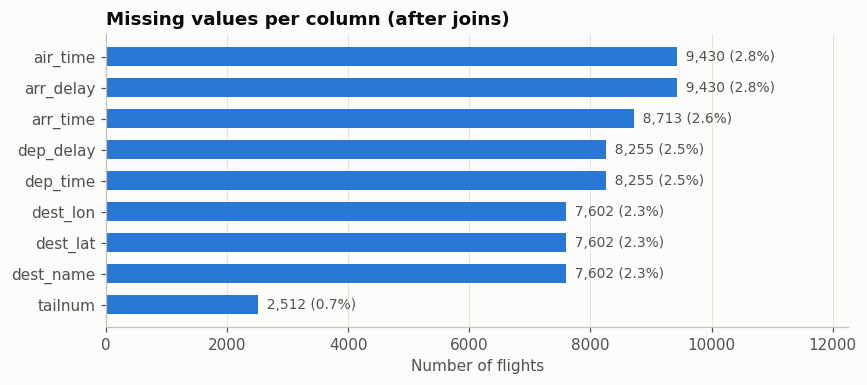

In [5]:
key = ["year", "month", "day", "carrier", "flight", "origin", "sched_dep_time"]
print("Exact duplicate rows      :", df.duplicated().sum())
print("Duplicate flight keys     :", df.duplicated(subset=key).sum())

# Scheduled times are HHMM integers -> check they are valid clock times
h, m = df.sched_dep_time // 100, df.sched_dep_time % 100
print("Invalid sched_dep_time    :", (~(h.between(0, 23) & m.between(0, 59))).sum())
print("hour/minute match schedule:", ((df.hour == h) & (df.minute == m)).mean().round(4))
print("Non-positive distances    :", (df.distance <= 0).sum())
print("Dates all in 2013         :", (df.year == 2013).all())

# Is dep_delay consistent with (dep_time - sched_dep_time)?  (mod 24h for flights departing after midnight)
to_min = lambda t: (t // 100) * 60 + t % 100
diff = to_min(df.dep_time) - to_min(df.sched_dep_time)
ok = ((diff - df.dep_delay) % 1440 == 0)[df.dep_delay.notna()]
print("dep_delay consistent with clock times:", f"{ok.mean():.4%}")

miss = df.isna().sum()
miss = miss[miss > 0].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(miss.index, miss.values, color=BLUE, height=0.6)
for i, v in enumerate(miss.values):
    ax.text(v, i, f"  {v:,} ({v/len(df):.1%})", va="center", color=INK2, fontsize=9)
ax.set_title("Missing values per column (after joins)")
ax.set_xlabel("Number of flights")
ax.set_xlim(0, miss.max() * 1.3)
no_grid(ax, "y")
plt.tight_layout(); plt.show()

**Interpretation.**

- **No duplicates**, neither exact rows nor duplicate flight keys (date + carrier + flight number + origin + scheduled time).
- **All scheduled times are valid clock times**, and the `hour`/`minute` columns agree with `sched_dep_time` on 100% of rows.
- **`dep_delay` agrees exactly with `dep_time − sched_dep_time`** (modulo 24h for departures after midnight) for 100% of flights. The target variable is therefore internally consistent and we can trust the labels.
- **Missing values** fall into two groups:
  1. `dep_time`, `dep_delay`, `arr_time`, `arr_delay` and `air_time` are missing together for about 8,200–9,400 flights. These are **cancelled flights** (no departure recorded). `arr_delay` has a few more missing values because some flights were diverted.
  2. `dest_name`, `dest_lat` and `dest_lon` are missing for the 7,602 Puerto Rico / Virgin Islands flights explained above.
- `tailnum` is missing for some flights, but we don't use it.

### 2.3 Cancelled flights

A flight without a recorded departure has no `dep_delay`, so it cannot be labelled and is **excluded from supervised learning**.

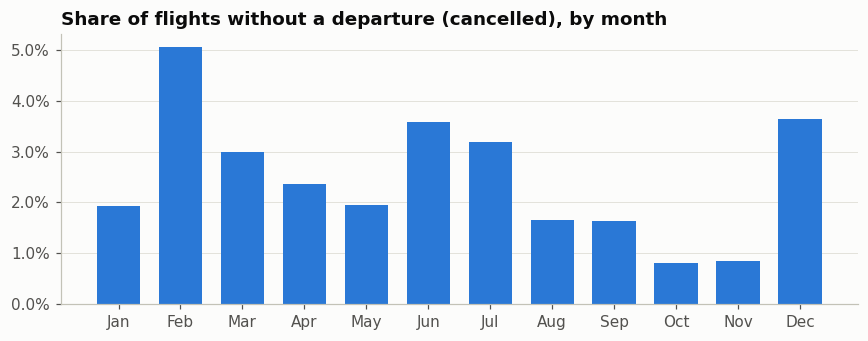

Cancelled / no departure recorded: 8,255 flights (2.45%)


In [6]:
df["date"] = pd.to_datetime(df[["year", "month", "day"]])
df["cancelled"] = df.dep_delay.isna()
canc = df.groupby("month").cancelled.mean()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(canc.index, canc.values, color=BLUE, width=0.7)
ax.set_xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
pct(ax, decimals=1)
ax.set_title("Share of flights without a departure (cancelled), by month")
no_grid(ax, "x")
plt.tight_layout(); plt.show()
print(f"Cancelled / no departure recorded: {df.cancelled.sum():,} flights ({df.cancelled.mean():.2%})")

**Interpretation.** 2.45% of flights have no recorded departure. Cancellations are **not uniform over the year**: they peak in **February (5%)**, when snowstorm *Nemo* hit the North-East on 8–9 Feb 2013. They are also elevated in **June–July** (thunderstorm season) and **December** (about 3.5%), and lowest in October–November (< 1%). Dropping cancelled flights could bias the labels, because the worst-disrupted days lose their worst flights. This is a known limitation. A future version could treat cancellation as a third class or count it as a "delay".

## 3. Feature construction and target

All features below can be computed **before** the flight departs:

| Feature | Definition | Why it may matter |
|---|---|---|
| `minute_of_day` | scheduled departure time in minutes after midnight | delays build up during the day |
| `weekday`, `is_weekend` | from the scheduled date | business vs. leisure traffic patterns |
| `days_to_holiday` | distance (days) to the nearest US federal holiday | holiday travel peaks |
| `daily_volume` | number of NYC departures scheduled that day | busy days → more congestion |
| `origin_hour_volume` | departures scheduled at the same airport in the same hour | runway and gate congestion |
| `distance` | route length in miles | short-haul vs. long-haul operations |
| `carrier`, `origin`, `dest` | categorical codes | airline, airport and route effects |

The two traffic features are computed from **all scheduled flights, including those later cancelled**, because a schedule is public in advance.

We deliberately **leave out `month`**. With a chronological split, the test months (Nov–Dec) never appear in training, so a tree would just treat "month 11/12" like "month 8". Section 4 shows that seasonality is strong, but this design cannot learn it from 8 months of data.

In [7]:
# ---- Schedule-based features (all known BEFORE departure) ----
df["sched_hour"] = df.sched_dep_time // 100
df["minute_of_day"] = df.sched_hour * 60 + df.sched_dep_time % 100
df["weekday"] = df.date.dt.dayofweek                      # 0 = Monday
df["weekday_name"] = df.date.dt.day_name().str[:3]
df["is_weekend"] = (df.weekday >= 5).astype(int)

# Days to the nearest US federal holiday (holiday travel peaks are known in advance)
hol = USFederalHolidayCalendar().holidays("2012-11-01", "2014-02-28")
udates = pd.Series(df.date.unique())
dist_to_hol = udates.apply(lambda d: int(np.abs((hol - d).days).min()))
df["days_to_holiday"] = df.date.map(dict(zip(udates, dist_to_hol)))

# Scheduled traffic (computed on ALL scheduled flights, including those later cancelled,
# because the schedule itself is public before the day of travel)
df["daily_volume"] = df.groupby("date").flight.transform("size")
df["origin_hour_volume"] = df.groupby(["date", "origin", "sched_hour"]).flight.transform("size")

# ---- Keep flights with an observed departure and build the target ----
mdl = df[~df.cancelled].copy()
mdl["delayed"] = (mdl.dep_delay >= 15).astype(int)
print(f"Flights available for supervised learning: {len(mdl):,}")
print(f"Delay rate (dep_delay >= 15 min): {mdl.delayed.mean():.2%}")

Flights available for supervised learning: 328,521
Delay rate (dep_delay >= 15 min): 22.19%


After removing cancelled flights, **328,521 flights** remain, and **22.2%** of them are delayed by 15 minutes or more.

### 3.1 The target variable

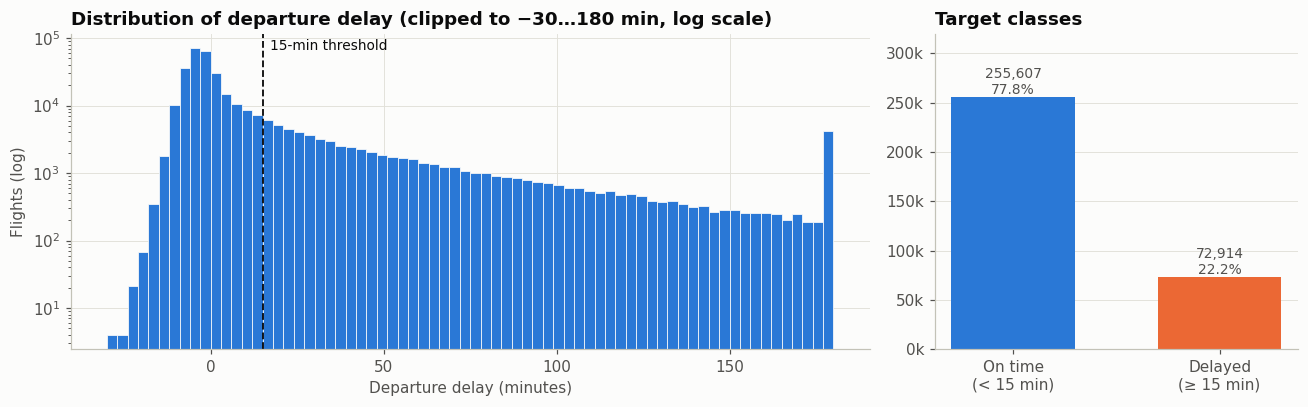

Median delay: -2 min | mean: 12.6 min | share early/on time (≤0): 60.9% | ≥60 min: 8.2% | max: 1301 min


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
clipped = mdl.dep_delay.clip(-30, 180)
ax.hist(clipped, bins=np.arange(-30, 182, 3), color=BLUE, edgecolor=SURFACE, linewidth=0.5)
ax.axvline(15, color=INK, lw=1.2, ls="--")
ax.text(17, ax.get_ylim()[1] * 0.9, "15-min threshold", color=INK, fontsize=9)
ax.set_yscale("log")
ax.set_title("Distribution of departure delay (clipped to −30…180 min, log scale)")
ax.set_xlabel("Departure delay (minutes)"); ax.set_ylabel("Flights (log)")

ax = axes[1]
counts = mdl.delayed.value_counts().sort_index()
bars = ax.bar(["On time\n(< 15 min)", "Delayed\n(≥ 15 min)"], counts.values, color=[BLUE, ORANGE], width=0.6)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:,}\n{v/counts.sum():.1%}", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_ylim(0, counts.max() * 1.25)
ax.set_title("Target classes")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
no_grid(ax, "x")
plt.tight_layout(); plt.show()

d = mdl.dep_delay
print(f"Median delay: {d.median():.0f} min | mean: {d.mean():.1f} min | "
      f"share early/on time (≤0): {(d<=0).mean():.1%} | ≥60 min: {(d>=60).mean():.1%} | max: {d.max():.0f} min")

**Interpretation.**

- The departure delay distribution is **strongly right-skewed**. The **median flight leaves 2 minutes early**, and 60.9% of flights leave on time or early. A long tail of large delays (8.2% of flights are ≥ 60 min late, the maximum is 1,301 min ≈ 21.7 h) pulls the **mean up to 12.6 min**. The spike at 180 is the clipped tail. This skew is why we predict a **binary** outcome rather than the delay in minutes, since a regression on minutes would be dominated by a few extreme events.
- The classes are **imbalanced: 77.8% on time vs. 22.2% delayed**. As a result, **accuracy is misleading**: a model that always says "on time" is 78% accurate but useless. We therefore focus on **precision, recall and F1** for the *delayed* class, as stated in the project plan, plus the threshold-free **ROC-AUC** and **PR-AUC**. We use `class_weight="balanced"` in the tree-based models so that they don't simply ignore the minority class.

## 4. Exploratory data analysis

### 4.1 Time of day

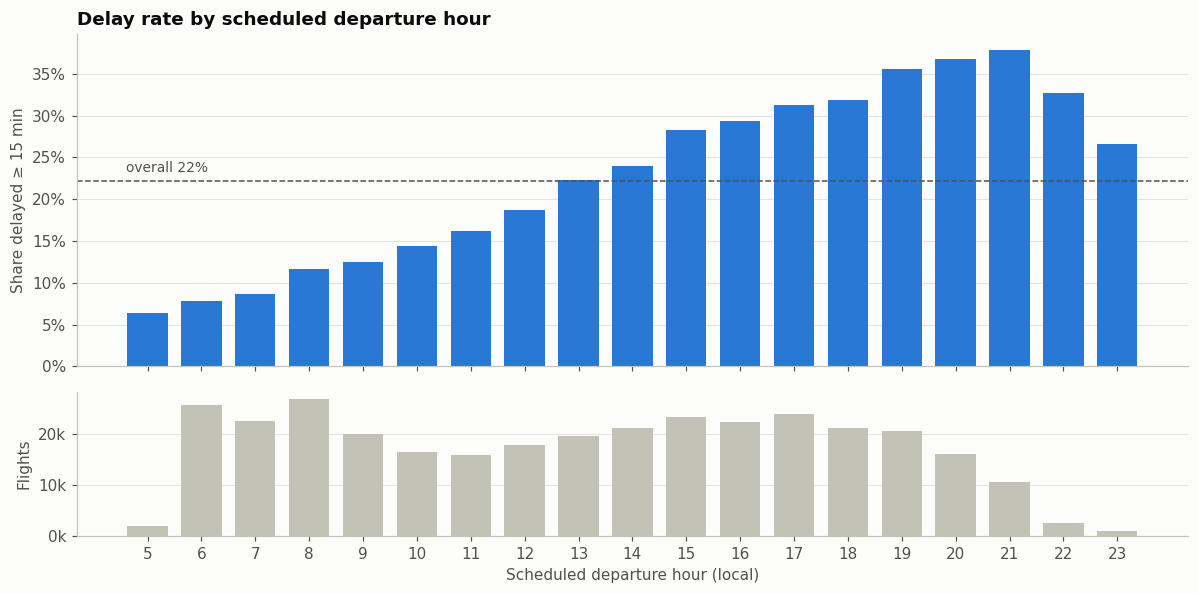

sched_hour,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
rate,0.063,0.078,0.086,0.117,0.125,0.144,0.162,0.187,0.223,0.240,0.282,0.293,0.313,0.318,0.356,0.368,0.378,0.326,0.266
n,"1,944.000","25,526.000","22,532.000","26,800.000","19,985.000","16,418.000","15,737.000","17,793.000","19,527.000","21,140.000","23,218.000","22,162.000","23,766.000","21,157.000","20,580.000","16,103.000","10,524.000","2,561.000","1,048.000"


In [9]:
by_hour = mdl.groupby("sched_hour").agg(rate=("delayed", "mean"), n=("delayed", "size"))
by_hour = by_hour[by_hour.n >= 100]

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, gridspec_kw={"height_ratios": [2.3, 1]})
ax = axes[0]
ax.bar(by_hour.index, by_hour.rate, color=BLUE, width=0.75)
ax.axhline(mdl.delayed.mean(), color=INK2, lw=1, ls="--")
ax.text(by_hour.index.min() - 0.4, mdl.delayed.mean() + 0.01, f"overall {mdl.delayed.mean():.0%}", color=INK2, fontsize=9)
pct(ax); no_grid(ax, "x")
ax.set_title("Delay rate by scheduled departure hour"); ax.set_ylabel("Share delayed ≥ 15 min")
ax = axes[1]
ax.bar(by_hour.index, by_hour.n, color=AXIS, width=0.75)
ax.set_ylabel("Flights"); ax.set_xlabel("Scheduled departure hour (local)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
ax.set_xticks(by_hour.index); no_grid(ax, "x")
plt.tight_layout(); plt.show()
display(by_hour.T)

**Interpretation.** Time of day shows **the clearest pattern in the whole dataset**. The delay rate rises almost steadily from **6% at 05:00 to 38% at 21:00**, six times higher. This fits the well-known **"delay propagation"** effect: aircraft fly several legs a day, so a delay early in the day is passed on to every later flight using the same aircraft, crew or gate. Early-morning flights start with "fresh" aircraft that were parked overnight. The small dip after 22:00 involves few flights (see the lower panel), mostly long-haul red-eyes. Departure hour is likely to be the most important model input.

### 4.2 Day of week and month

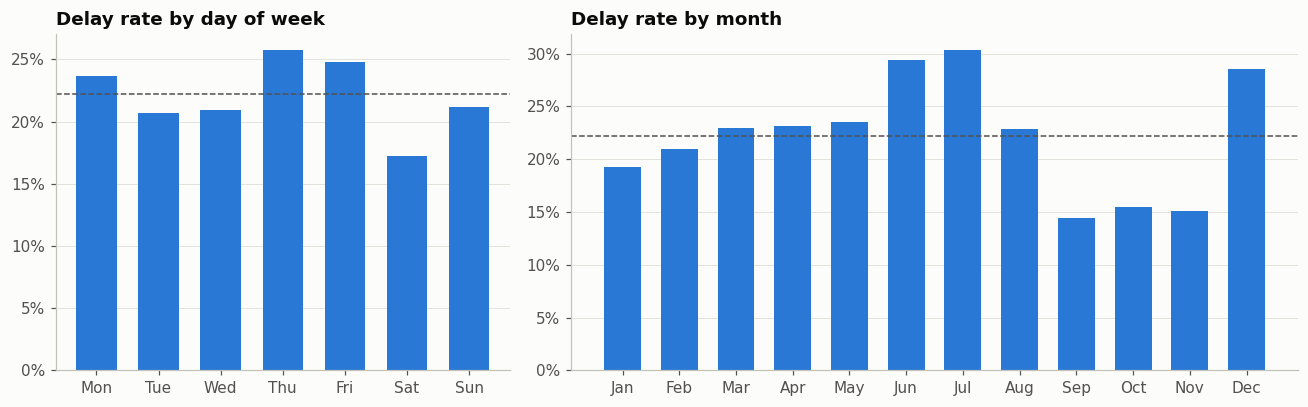

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
delay rate,0.192,0.209,0.229,0.232,0.235,0.294,0.303,0.229,0.144,0.154,0.150,0.286


In [10]:
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
DAYS = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
by_wd = mdl.groupby("weekday").delayed.mean()
by_m = mdl.groupby("month").delayed.mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].bar(DAYS, by_wd.values, color=BLUE, width=0.65)
axes[0].set_title("Delay rate by day of week")
axes[1].bar(MONTHS, by_m.values, color=BLUE, width=0.65)
axes[1].set_title("Delay rate by month")
for ax in axes:
    pct(ax); no_grid(ax, "x")
    ax.axhline(mdl.delayed.mean(), color=INK2, lw=1, ls="--")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"delay rate": by_m.values}, index=MONTHS).T)

**Interpretation.**

- **Day of week:** Thursday (25.7%) and Friday (24.8%) are the worst days and **Saturday the best (17.2%)**. This follows business travel and weekend-getaway traffic, since Saturday has the lowest flight volume. The effect is real but smaller than the hourly effect (about 8.5 percentage points between the best and worst day, compared with about 30 points between hours).
- **Month:** there is strong seasonality. **June–July (29–30%)** are the worst months (summer thunderstorms and peak travel), followed by **December (28.6%)** (winter weather and holidays). **September–November are by far the calmest (14–15%)**.
- **Consequence for evaluation:** our validation period (Sep–Oct, 14.9% delayed) is much "easier" than both the training period (24.1%) and the test period (Nov–Dec, 21.8%, which includes a bad December). The **base rate shifts between splits**, which will affect the chosen decision thresholds (see Section 6).

### 4.3 Interaction between weekday and hour

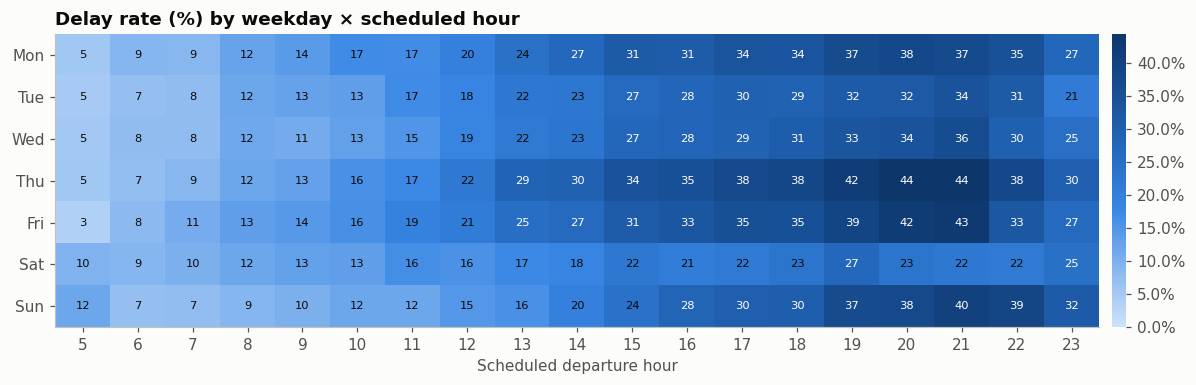

In [11]:
pv = mdl[mdl.sched_hour.between(5, 23)].pivot_table(index="weekday", columns="sched_hour", values="delayed", aggfunc="mean")
fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.imshow(pv.values, cmap=SEQ, aspect="auto", vmin=0)
ax.set_yticks(range(7), DAYS); ax.set_xticks(range(pv.shape[1]), pv.columns)
ax.set_xlabel("Scheduled departure hour"); ax.grid(False)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        v = pv.values[i, j]
        ax.text(j, i, f"{v*100:.0f}", ha="center", va="center", fontsize=7.5,
                color="white" if v > pv.values.max() * 0.55 else INK)
cb = fig.colorbar(im, ax=ax, pad=0.01, format=mtick.PercentFormatter(1.0))
cb.outline.set_visible(False)
ax.set_title("Delay rate (%) by weekday × scheduled hour")
plt.tight_layout(); plt.show()

**Interpretation.** The heatmap combines the two previous effects. The worst slots are **Thursday and Friday evenings (19:00–21:00: 39–44% delayed)**, and the best are **early mornings on any day (3–10%)**. **Saturday evenings are clearly less delay-prone (22–27%)** than other evenings, and the evening peak is "flatter" on weekends. The hour effect is present on **every** day of the week, so the two variables mostly add up rather than interact strongly. That suits both linear-style and tree-based models.

### 4.4 Delay rate over the year

The shaded regions show the chronological train / validation / test split used later.

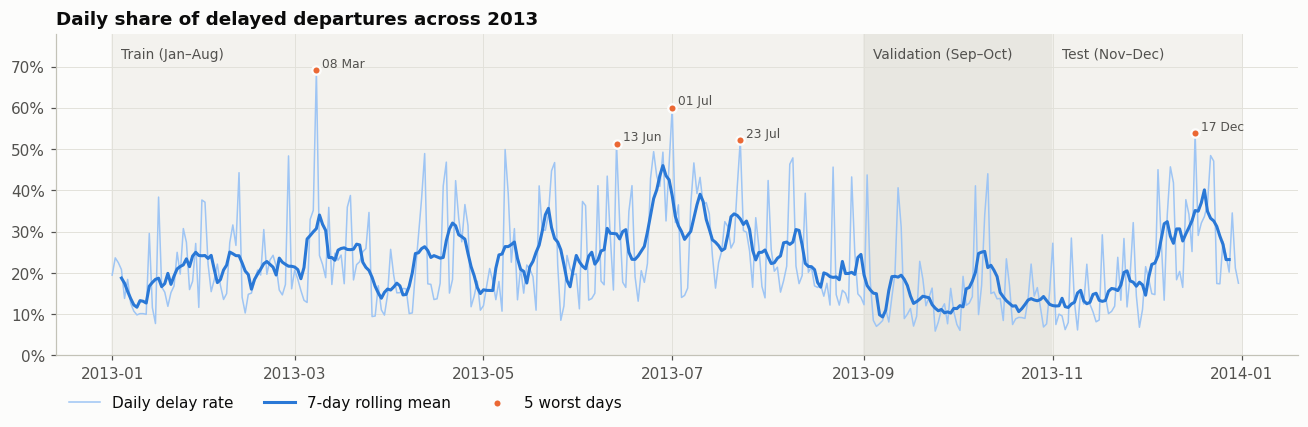

In [12]:
daily = mdl.groupby("date").delayed.mean()
roll = daily.rolling(7, center=True).mean()
fig, ax = plt.subplots(figsize=(12, 4))
spans = [("2013-01-01", "2013-08-31", "Train (Jan–Aug)"), ("2013-09-01", "2013-10-31", "Validation (Sep–Oct)"),
         ("2013-11-01", "2013-12-31", "Test (Nov–Dec)")]
for (a, b, lab), shade in zip(spans, ["#f3f2ee", "#e8e7e1", "#f3f2ee"]):
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b) + pd.Timedelta(days=1), color=shade, zorder=0)
    ax.text(pd.Timestamp(a) + pd.Timedelta(days=3), 0.72, lab, fontsize=9, color=INK2)
ax.plot(daily.index, daily.values, color="#9ec5f4", lw=1, label="Daily delay rate")
ax.plot(roll.index, roll.values, color=BLUE, lw=2, label="7-day rolling mean")
worst = daily.nlargest(5)
ax.scatter(worst.index, worst.values, color=ORANGE, s=30, zorder=3, edgecolor=SURFACE, linewidth=1.5, label="5 worst days")
for d0, v in worst.items():
    ax.annotate(d0.strftime("%d %b"), (d0, v), xytext=(4, 2), textcoords="offset points", fontsize=8, color=INK2)
ax.set_ylim(0, 0.78); pct(ax)
ax.set_title("Daily share of delayed departures across 2013")
ax.legend(loc="upper left", ncol=3, bbox_to_anchor=(0, -0.08))
plt.tight_layout(); plt.show()

**Interpretation.** This chart explains much of what follows in the modelling sections. The delay rate is **extremely volatile from day to day**: it ranges from below 10% on calm days to **69% on 8 March** (a winter storm) and 60% on 1 July, with **17 December** the worst day in the test period. These spikes are caused by **weather and airport-wide disruptions**, which **cannot be predicted from schedule features alone** (a flight's schedule doesn't change on a stormy day). A large part of the variance in the target therefore sits outside the reach of our current inputs, which puts a ceiling on the performance we can expect from this first model. The 7-day mean also confirms the seasonal pattern: high in early summer and in late December, low in autumn.

### 4.5 Origin airport

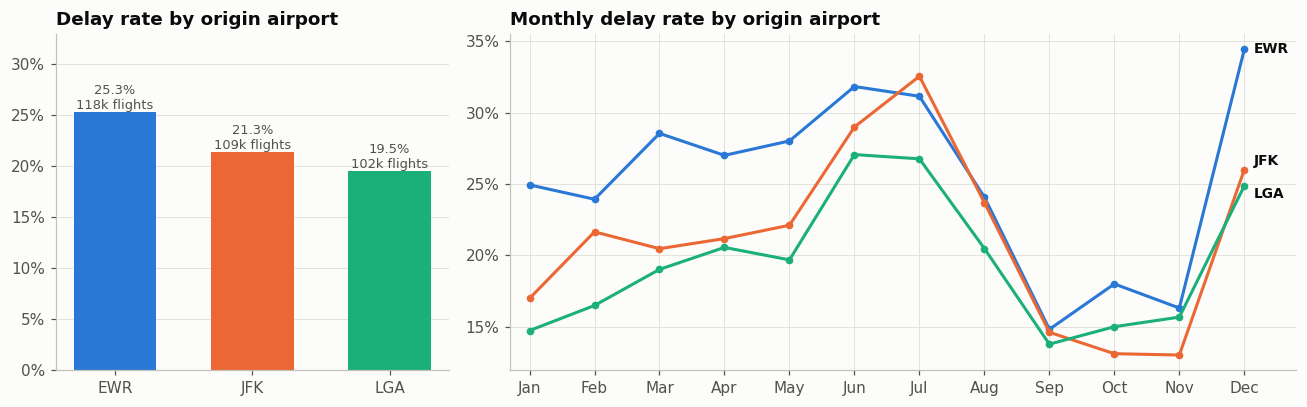

In [13]:
by_o = mdl.groupby(["origin", "origin_name"]).agg(rate=("delayed", "mean"), n=("delayed", "size")).reset_index()
om = mdl.pivot_table(index="month", columns="origin", values="delayed", aggfunc="mean")
ORIGIN_COL = {"EWR": BLUE, "JFK": ORANGE, "LGA": AQUA}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 2]})
ax = axes[0]
bars = ax.bar(by_o.origin, by_o.rate, color=[ORIGIN_COL[o] for o in by_o.origin], width=0.6)
for b, (r, n) in zip(bars, zip(by_o.rate, by_o.n)):
    ax.text(b.get_x() + b.get_width()/2, r, f"{r:.1%}\n{n/1000:.0f}k flights", ha="center", va="bottom", fontsize=8.5, color=INK2)
ax.set_ylim(0, by_o.rate.max() * 1.3); pct(ax); no_grid(ax, "x")
ax.set_title("Delay rate by origin airport")
ax = axes[1]
nudge = {"EWR": 0, "JFK": 0.006, "LGA": -0.006}
for o in om.columns:
    ax.plot(om.index, om[o], color=ORIGIN_COL[o], marker="o", ms=4)
    ax.text(12.15, om[o].iloc[-1] + nudge[o], o, color=INK, va="center", fontsize=9, fontweight="bold")
ax.set_xticks(range(1, 13), MONTHS); ax.set_xlim(0.7, 12.8); pct(ax)
ax.set_title("Monthly delay rate by origin airport")
plt.tight_layout(); plt.show()

**Interpretation.** **Newark (EWR) has the highest delay rate (25.3%)**, followed by JFK (21.3%) and LaGuardia (19.5%). The monthly lines show that EWR is the worst airport in most months and that the gap **grows sharply in December (EWR 34% vs. about 25% for JFK and LGA)**. JFK, the main long-haul hub, is worst in June. All three airports follow the same seasonal shape, so the airport effect is an "offset" on top of a shared regional (weather) signal.

### 4.6 Airline

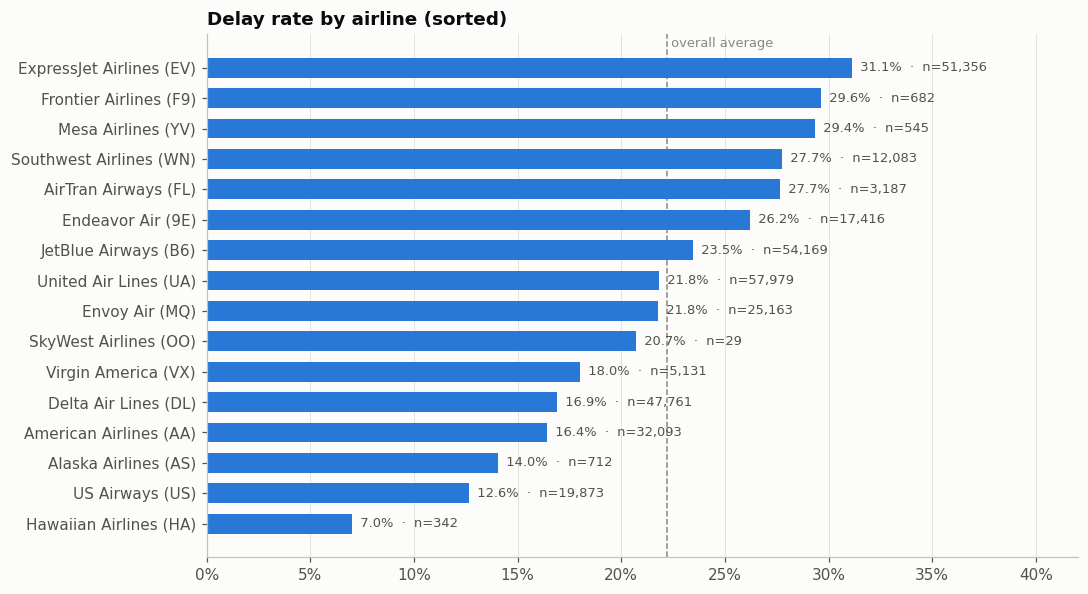

In [14]:
by_c = (mdl.groupby(["carrier", "airline"]).agg(rate=("delayed", "mean"), n=("delayed", "size"),
                                                  mean_delay=("dep_delay", "mean"))
        .reset_index().sort_values("rate"))
fig, ax = plt.subplots(figsize=(10, 5.5))
labels = [f"{a.replace(' Inc.', '').replace(' Co.', '').replace(' Corporation', '')} ({c})" for a, c in zip(by_c.airline, by_c.carrier)]
ax.barh(labels, by_c.rate, color=BLUE, height=0.65)
for i, (r, n) in enumerate(zip(by_c.rate, by_c.n)):
    ax.text(r, i, f"  {r:.1%}  ·  n={n:,}", va="center", fontsize=8.5, color=INK2)
ax.axvline(mdl.delayed.mean(), color=MUTED, lw=1, ls="--", zorder=0)
ax.text(mdl.delayed.mean(), len(by_c) - 0.3, " overall average", color=MUTED, fontsize=8.5)
ax.set_xlim(0, by_c.rate.max() * 1.35); pct(ax, "x"); no_grid(ax, "y")
ax.set_title("Delay rate by airline (sorted)")
plt.tight_layout(); plt.show()

**Interpretation.** Airlines differ a lot. **ExpressJet (EV) has a 31% delay rate on 51k flights**, so it is both the largest group and the most delay-prone. EV is a regional carrier flying many short feeder routes out of EWR, which partly explains the EWR result above. At the other end, **US Airways (12.6%), American (16.4%) and Delta (16.9%)** are well below average. Hawaiian (7%), SkyWest and Mesa have very few flights (n < 700), so their rates are **unreliable**. The one-hot encoder groups such rare categories into an *"infrequent"* bucket (`min_frequency=100`) to avoid overfitting them. Carrier should be a strong model input.

### 4.7 Destination and distance

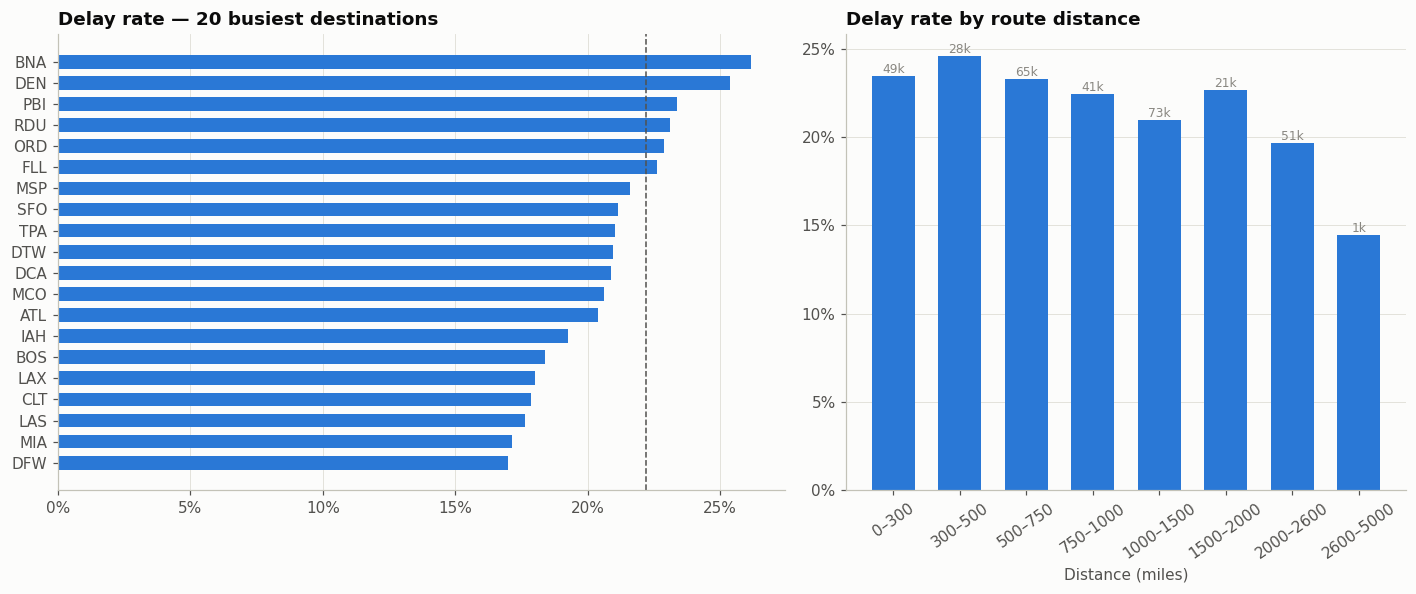

In [15]:
top_dest = (mdl.groupby(["dest", "dest_name"], dropna=False)
            .agg(rate=("delayed", "mean"), n=("delayed", "size"), distance=("distance", "mean"))
            .reset_index().nlargest(20, "n").sort_values("rate"))
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.barh(top_dest.dest, top_dest.rate, color=BLUE, height=0.65)
ax.axvline(mdl.delayed.mean(), color=INK2, lw=1, ls="--")
pct(ax, "x"); no_grid(ax, "y")
ax.set_title("Delay rate — 20 busiest destinations")

# Distance bins
bins = [0, 300, 500, 750, 1000, 1500, 2000, 2600, 5000]
mdl["distance_bin"] = pd.cut(mdl.distance, bins)
by_dist = mdl.groupby("distance_bin", observed=True).agg(rate=("delayed", "mean"), n=("delayed", "size"))
ax = axes[1]
lbl = [f"{int(i.left)}–{int(i.right)}" for i in by_dist.index]
ax.bar(lbl, by_dist.rate, color=BLUE, width=0.65)
for i, n in enumerate(by_dist.n):
    ax.text(i, by_dist.rate.iloc[i], f"{n/1000:.0f}k", ha="center", va="bottom", fontsize=8, color=MUTED)
ax.tick_params(axis="x", rotation=35); pct(ax); no_grid(ax, "x")
ax.set_xlabel("Distance (miles)")
ax.set_title("Delay rate by route distance")
plt.tight_layout(); plt.show()

**Interpretation.**

- Among the 20 busiest destinations, the delay rate ranges from about **17% (DFW, MIA, LAS)** to **about 26% (BNA Nashville, DEN Denver)**. These differences are smaller than the airline or hour effects, and they are partly confounded with the airline: a destination served mostly by EV inherits EV's delay rate.
- **Distance:** short and medium routes (< 750 mi) have about 23–25% delays, and the rate falls for long-haul routes, **down to 14% above 2,600 miles** (mostly the Hawaii routes, few flights). Long-haul flights are often the first flights of an aircraft's day or have more schedule buffer. The relationship is weak and not perfectly monotonic.

### 4.8 Congestion and holidays

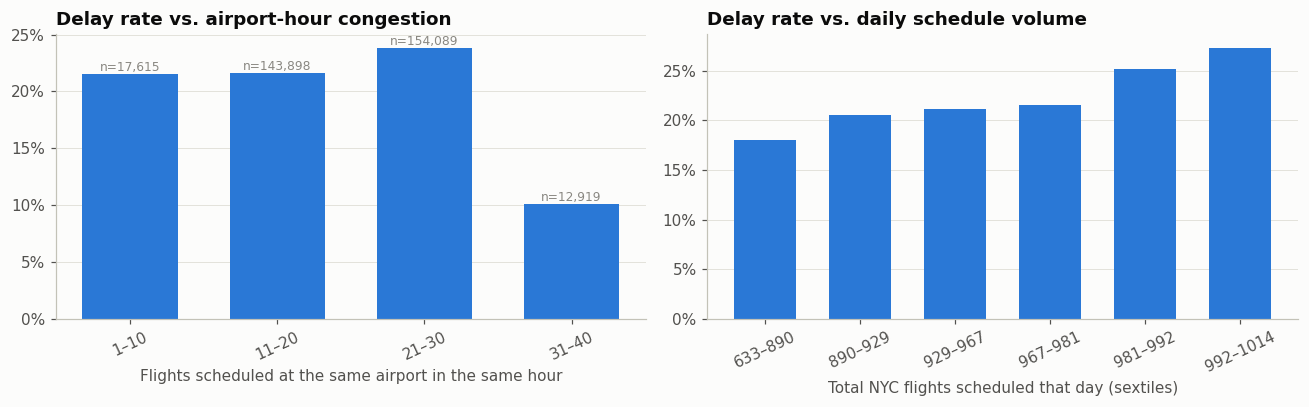

Delay rate by days to nearest federal holiday (10 = 10+):


days_to_holiday,0,1,2,3,4,5,6,7,8,9,10
delay rate,0.183,0.205,0.189,0.256,0.251,0.216,0.208,0.238,0.218,0.219,0.223


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ohv = pd.cut(mdl.origin_hour_volume, [0, 10, 20, 30, 40, 50, 60, 100])
g = mdl.groupby(ohv, observed=True).delayed.agg(["mean", "size"])
axes[0].bar([f"{int(i.left)+1}–{int(i.right)}" for i in g.index], g["mean"], color=BLUE, width=0.65)
for i, (r, n) in enumerate(zip(g["mean"], g["size"])):
    axes[0].text(i, r, f"n={n:,}", ha="center", va="bottom", fontsize=8, color=MUTED)
axes[0].set_xlabel("Flights scheduled at the same airport in the same hour")
axes[0].set_title("Delay rate vs. airport-hour congestion")
dv = pd.qcut(mdl.daily_volume, 6)
g2 = mdl.groupby(dv, observed=True).delayed.mean()
axes[1].bar([f"{int(i.left)}–{int(i.right)}" for i in g2.index], g2.values, color=BLUE, width=0.65)
axes[1].set_xlabel("Total NYC flights scheduled that day (sextiles)")
axes[1].set_title("Delay rate vs. daily schedule volume")
for ax in axes:
    pct(ax); no_grid(ax, "x"); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

hol_rate = mdl.groupby(mdl.days_to_holiday.clip(upper=10)).delayed.mean()
print("Delay rate by days to nearest federal holiday (10 = 10+):")
display(hol_rate.to_frame("delay rate").T)

**Interpretation.**

- **Airport-hour congestion:** the relationship is **not monotonic**. Hours with 21–30 scheduled departures are slightly worse, but the busiest bin (31–40) has *fewer* delays. Those peak slots are early-morning banks (06:00–08:00), when the system is "fresh", so this is a **confounding effect of time of day** and not a causal "congestion helps" result. The tree models can untangle this because they see both features.
- **Daily volume:** busier days have more delays (18% on the quietest sixth of days vs. 27% on the busiest). Volume, however, is itself seasonal (summer is busy and bad), so this may also be confounded.
- **Holidays:** the table shows no simple pattern. The holiday day itself is slightly *better* (fewer business travellers), while 3–4 days away is slightly worse. This is a weak, noisy signal.

## 5. Train / validation / test split

As planned, the split is **chronological**. This mimics real use (train on the past, predict the future) and avoids leakage from neighbouring days with the same weather.

,period,flights,share of data,delay rate
train,Jan–Aug,218601,0.665,0.241
validation,Sep–Oct,55775,0.170,0.149
test,Nov–Dec,54145,0.165,0.218


Test destinations never seen in training: ['ILM', 'LEX']


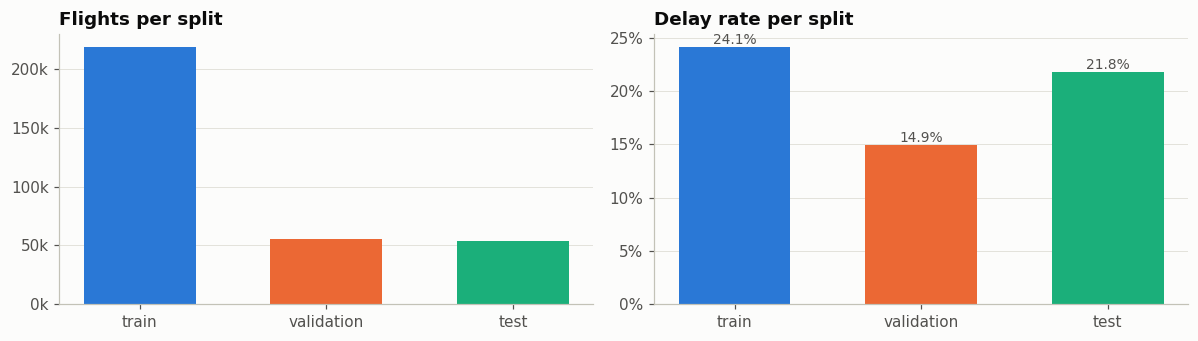

In [17]:
CAT_FEATS = ["carrier", "origin", "dest"]
NUM_FEATS = ["minute_of_day", "weekday", "is_weekend", "days_to_holiday", "distance",
             "daily_volume", "origin_hour_volume"]
EXTRA = ["sched_hour"]           # only used by the hour-of-day baseline
TARGET = "delayed"

train = mdl[mdl.month <= 8]
val = mdl[mdl.month.isin([9, 10])]
test = mdl[mdl.month >= 11]
X_tr, y_tr = train[CAT_FEATS + NUM_FEATS + EXTRA], train[TARGET]
X_va, y_va = val[CAT_FEATS + NUM_FEATS + EXTRA], val[TARGET]
X_te, y_te = test[CAT_FEATS + NUM_FEATS + EXTRA], test[TARGET]

split_info = pd.DataFrame({
    "period": ["Jan–Aug", "Sep–Oct", "Nov–Dec"],
    "flights": [len(train), len(val), len(test)],
    "share of data": [len(train)/len(mdl), len(val)/len(mdl), len(test)/len(mdl)],
    "delay rate": [y_tr.mean(), y_va.mean(), y_te.mean()]}, index=["train", "validation", "test"])
display(split_info)

unseen_dest = sorted(set(test.dest) - set(train.dest))
print("Test destinations never seen in training:", unseen_dest or "none")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
cols = [BLUE, ORANGE, AQUA]
axes[0].bar(split_info.index, split_info.flights, color=cols, width=0.6)
axes[0].set_title("Flights per split"); axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
axes[1].bar(split_info.index, split_info["delay rate"], color=cols, width=0.6)
for i, v in enumerate(split_info["delay rate"]):
    axes[1].text(i, v, f"{v:.1%}", ha="center", va="bottom", fontsize=9, color=INK2)
axes[1].set_title("Delay rate per split"); pct(axes[1])
for ax in axes: no_grid(ax, "x")
plt.tight_layout(); plt.show()

**Interpretation.** The training set holds two-thirds of the data. The **delay rate differs strongly between splits**: 24.1% in training, **14.9% in validation**, 21.8% in test. A model that works well in Sep–Oct is being judged on Nov–Dec, which include the holiday and winter-storm period. The test set contains only two destinations never seen in training (ILM and LEX, a handful of flights). The encoder handles them as "unknown/infrequent" without errors.

## 6. Modelling

### 6.1 Preprocessing and evaluation helpers

- **Encoding:** `OneHotEncoder` for `carrier`, `origin` and `dest`, **fitted on the training data only**. Categories seen fewer than 100 times are grouped into one "infrequent" column, and unseen categories go there too. Numeric features are passed through unchanged (tree models don't need scaling).
- **Threshold selection:** tree models output a probability. To get a delayed / not-delayed decision we pick the threshold that **maximises F1 on the validation set**, then apply that same threshold to the test set.
- **Baselines** (as promised in the project plan):
  1. **Majority class**: always predicts "on time". It sets the accuracy floor and shows why accuracy alone is misleading.
  2. **Hour-of-day rate**: predicts, for each flight, the training-set delay rate of its scheduled departure hour. This simple one-feature rule is a **strong baseline** after Section 4.1, so the ML models must beat it to show their value.

In [18]:
def make_preprocessor(num_feats=None):
    """One-hot encode categories (fitted on training data only) and pass numeric features through."""
    return ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False), CAT_FEATS),
         ("num", "passthrough", NUM_FEATS if num_feats is None else num_feats)],
        verbose_feature_names_out=False)

class HourRateBaseline(BaseEstimator, ClassifierMixin):
    """Predicts the training-set delay rate of the flight's scheduled departure hour."""
    def fit(self, X, y):
        self.rates_ = pd.Series(np.asarray(y)).groupby(X["sched_hour"].values).mean()
        self.default_ = float(np.mean(y))
        self.classes_ = np.array([0, 1])
        return self
    def predict_proba(self, X):
        p = X["sched_hour"].map(self.rates_).fillna(self.default_).values
        return np.column_stack([1 - p, p])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    i = int(np.nanargmax(f1[:-1]))
    return float(thr[i])

def scores(name, y, p, thr):
    yhat = (p >= thr).astype(int)
    return {"model": name, "threshold": thr, "accuracy": accuracy_score(y, yhat),
            "precision": precision_score(y, yhat, zero_division=0), "recall": recall_score(y, yhat),
            "F1": f1_score(y, yhat), "ROC-AUC": roc_auc_score(y, p) if len(np.unique(p)) > 1 else 0.5,
            "PR-AUC": average_precision_score(y, p)}

pre = make_preprocessor().fit(X_tr)
print("Model input matrix:", pre.transform(X_tr.head()).shape[1], "columns after encoding")

Model input matrix: 117 columns after encoding


### 6.2 Baselines

In [19]:
models, val_proba = {}, {}

models["Majority class"] = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
models["Hour-of-day rate"] = HourRateBaseline().fit(X_tr, y_tr)
for name in models:
    val_proba[name] = models[name].predict_proba(X_va)[:, 1]
print("Baselines fitted.")

Baselines fitted.


### 6.3 Decision tree: choosing the depth

We train trees with increasing `max_depth` (with `min_samples_leaf=50` and balanced class weights) and compare train and validation performance. The main selection metric is **PR-AUC** (average precision), which suits an imbalanced target better than ROC-AUC.

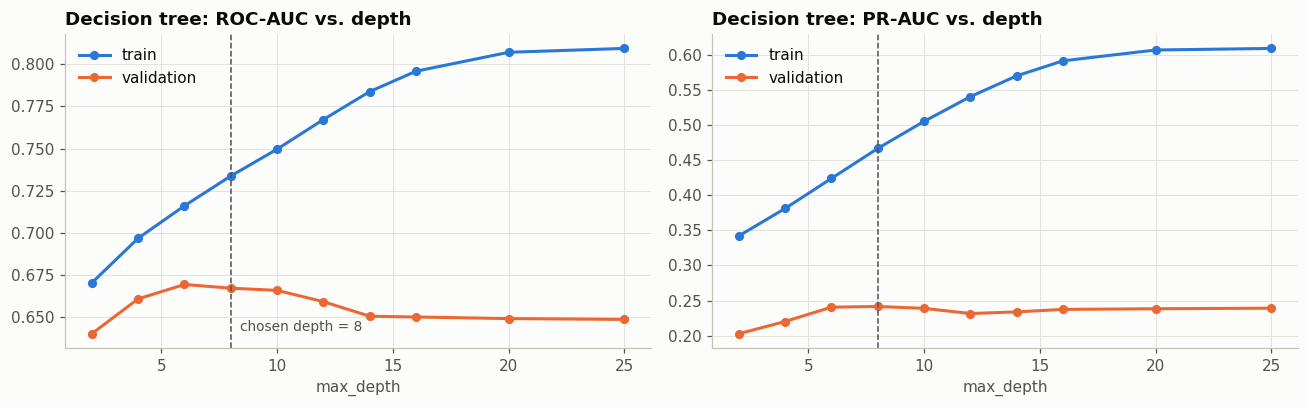

,train ROC-AUC,val ROC-AUC,train PR-AUC,val PR-AUC
max_depth,,,,
2,0.670,0.640,0.342,0.203
4,0.697,0.661,0.381,0.220
6,0.716,0.669,0.424,0.241
8,0.734,0.667,0.466,0.242
10,0.750,0.666,0.505,0.239
12,0.767,0.659,0.540,0.231
14,0.784,0.651,0.570,0.234
16,0.796,0.650,0.591,0.237
20,0.807,0.649,0.606,0.238


In [20]:
depths = [2, 4, 6, 8, 10, 12, 14, 16, 20, 25]
rows = []
for d in depths:
    pipe = Pipeline([("pre", make_preprocessor()),
                     ("clf", DecisionTreeClassifier(max_depth=d, min_samples_leaf=50,
                                                    class_weight="balanced", random_state=RANDOM_STATE))]).fit(X_tr, y_tr)
    p_tr, p_va = pipe.predict_proba(X_tr)[:, 1], pipe.predict_proba(X_va)[:, 1]
    rows.append({"max_depth": d, "train ROC-AUC": roc_auc_score(y_tr, p_tr), "val ROC-AUC": roc_auc_score(y_va, p_va),
                 "train PR-AUC": average_precision_score(y_tr, p_tr), "val PR-AUC": average_precision_score(y_va, p_va)})
tree_sweep = pd.DataFrame(rows).set_index("max_depth")
best_depth = int(tree_sweep["val PR-AUC"].idxmax())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, metric in zip(axes, ["ROC-AUC", "PR-AUC"]):
    ax.plot(depths, tree_sweep[f"train {metric}"], color=BLUE, marker="o", ms=5, label="train")
    ax.plot(depths, tree_sweep[f"val {metric}"], color=ORANGE, marker="o", ms=5, label="validation")
    ax.axvline(best_depth, color=INK2, lw=1, ls="--")
    ax.set_xlabel("max_depth"); ax.set_title(f"Decision tree: {metric} vs. depth")
    ax.legend()
axes[0].text(best_depth + 0.4, axes[0].get_ylim()[0] + 0.01, f"chosen depth = {best_depth}", fontsize=9, color=INK2)
plt.tight_layout(); plt.show()
display(tree_sweep)

**Interpretation.** The plot shows the **bias–variance trade-off**. Training performance keeps rising with depth (train PR-AUC 0.34 → 0.61), but **validation performance peaks at depth 6–8 (PR-AUC about 0.24, ROC-AUC about 0.67) and then declines slowly**. Deeper trees memorise training-period patterns (specific days, specific carrier × hour combinations) that don't carry over to the autumn. We keep **`max_depth = 8`**. The widening gap between the train and validation curves is overfitting.

In [21]:
models["Decision tree"] = Pipeline([("pre", make_preprocessor()),
                                    ("clf", DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=50,
                                                                   class_weight="balanced", random_state=RANDOM_STATE))]).fit(X_tr, y_tr)
val_proba["Decision tree"] = models["Decision tree"].predict_proba(X_va)[:, 1]
print(f"Decision tree (max_depth={best_depth}) — validation PR-AUC: {average_precision_score(y_va, val_proba['Decision tree']):.3f}")

Decision tree (max_depth=8) — validation PR-AUC: 0.242


### 6.4 Random Forest: small hyper-parameter grid

A Random Forest averages many decorrelated deep trees (bootstrapped samples, random feature subsets with `max_features="sqrt"`). This should reduce the variance seen above. We search a small grid over depth and minimum leaf size (150 trees each, about 5 s per fit).

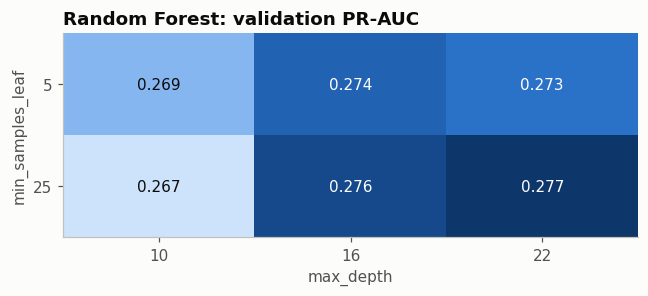

,max_depth,min_samples_leaf,val ROC-AUC,val PR-AUC,fit seconds
0,10,5,0.684,0.269,4.589
1,10,25,0.683,0.267,4.586
2,16,5,0.688,0.274,5.308
3,16,25,0.689,0.276,4.950
4,22,5,0.688,0.273,5.406
5,22,25,0.691,0.277,5.304


Chosen Random Forest settings (max_depth, min_samples_leaf): (22, 25)


In [22]:
grid = [(d, l) for d in [10, 16, 22] for l in [5, 25]]
rows, rf_fits = [], {}
for d, l in grid:
    t0 = time.time()
    pipe = Pipeline([("pre", make_preprocessor()),
                     ("clf", RandomForestClassifier(n_estimators=150, max_depth=d, min_samples_leaf=l,
                                                    max_features="sqrt", class_weight="balanced_subsample",
                                                    n_jobs=-1, random_state=RANDOM_STATE))]).fit(X_tr, y_tr)
    p_va = pipe.predict_proba(X_va)[:, 1]
    rows.append({"max_depth": d, "min_samples_leaf": l, "val ROC-AUC": roc_auc_score(y_va, p_va),
                 "val PR-AUC": average_precision_score(y_va, p_va), "fit seconds": time.time() - t0})
    rf_fits[(d, l)] = (pipe, p_va)
rf_grid = pd.DataFrame(rows)
best = rf_grid.loc[rf_grid["val PR-AUC"].idxmax()]
best_rf_key = (int(best.max_depth), int(best.min_samples_leaf))

hm = rf_grid.pivot(index="min_samples_leaf", columns="max_depth", values="val PR-AUC")
fig, ax = plt.subplots(figsize=(6, 2.8))
im = ax.imshow(hm.values, cmap=SEQ, aspect="auto")
ax.set_xticks(range(hm.shape[1]), hm.columns); ax.set_yticks(range(hm.shape[0]), hm.index)
ax.set_xlabel("max_depth"); ax.set_ylabel("min_samples_leaf"); ax.grid(False)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=10,
                color="white" if v > np.nanmean(hm.values) else INK)
ax.set_title("Random Forest: validation PR-AUC")
plt.tight_layout(); plt.show()
display(rf_grid.round(3))
print("Chosen Random Forest settings (max_depth, min_samples_leaf):", best_rf_key)

models["Random Forest"] = rf_fits[best_rf_key][0]
val_proba["Random Forest"] = rf_fits[best_rf_key][1]

**Interpretation.** All Random Forest settings beat the single tree on validation (**PR-AUC 0.267–0.277 vs. 0.242**; ROC-AUC 0.68–0.69 vs. 0.67). This is the expected benefit of **averaging**: deeper forests no longer overfit the way a single deep tree does. The grid surface is **flat** (all values within 0.01), so the model is not very sensitive to these settings. We keep **`max_depth=22`, `min_samples_leaf=25`**.

### 6.5 Validation results and decision thresholds

,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,,
Majority class,0.500,0.851,0.000,0.000,0.000,0.500,0.149
Hour-of-day rate,0.308,0.618,0.222,0.625,0.328,0.655,0.219
Decision tree,0.521,0.611,0.224,0.649,0.333,0.667,0.242
Random Forest,0.550,0.680,0.249,0.565,0.345,0.691,0.277


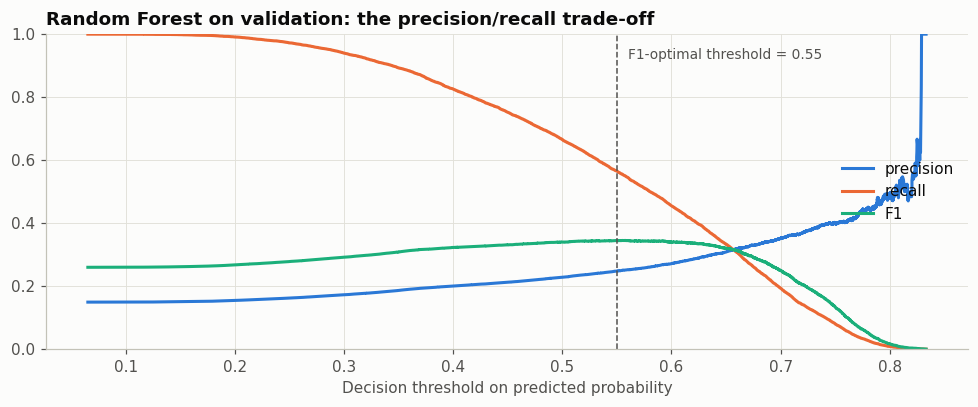

In [23]:
thresholds = {name: (0.5 if name == "Majority class" else best_f1_threshold(y_va, p)) for name, p in val_proba.items()}
val_results = pd.DataFrame([scores(n, y_va, p, thresholds[n]) for n, p in val_proba.items()]).set_index("model")
display(val_results)

# Precision / recall / F1 as a function of the decision threshold (Random Forest, validation set)
prec, rec, thr = precision_recall_curve(y_va, val_proba["Random Forest"])
f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(thr, prec[:-1], color=BLUE, label="precision")
ax.plot(thr, rec[:-1], color=ORANGE, label="recall")
ax.plot(thr, f1[:-1], color=AQUA, label="F1")
ax.axvline(thresholds["Random Forest"], color=INK2, lw=1, ls="--")
ax.text(thresholds["Random Forest"] + 0.01, 0.92, f"F1-optimal threshold = {thresholds['Random Forest']:.2f}", fontsize=9, color=INK2)
ax.set_xlabel("Decision threshold on predicted probability"); ax.set_ylim(0, 1)
ax.set_title("Random Forest on validation: the precision/recall trade-off")
ax.legend(loc="center right")
plt.tight_layout(); plt.show()

**Interpretation (validation, Sep–Oct).**

- The **majority-class baseline reaches 85% accuracy with 0 recall**. This confirms that accuracy is not a useful metric here.
- The **Random Forest is the best model on every threshold-free metric** (ROC-AUC 0.691, PR-AUC 0.277) and also on F1 (0.345), ahead of the decision tree (0.333) and the hour-of-day baseline (0.328).
- **The F1-optimal thresholds are low** for the baseline (0.31). For the tree models (about 0.52–0.55) they *look* higher only because `class_weight="balanced"` inflates their probabilities (see the calibration plot later).
- The precision/recall chart shows the **business trade-off**: a lower threshold flags more flights, catching more true delays (higher recall) at the cost of more false alarms (lower precision). Which point is "best" depends on the use case. A passenger alert app would prefer high recall, and an airline reallocating staff would prefer high precision.

## 7. Final evaluation on the test set (Nov–Dec 2013)

The test set was not used for any decision above. The models and thresholds are exactly those selected on validation.

,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,,
Majority class,0.500,0.782,0.000,0.000,0.000,0.500,0.218
Hour-of-day rate,0.308,0.614,0.303,0.594,0.402,0.642,0.303
Decision tree,0.521,0.612,0.289,0.534,0.375,0.627,0.287
Random Forest,0.550,0.666,0.318,0.465,0.378,0.652,0.320


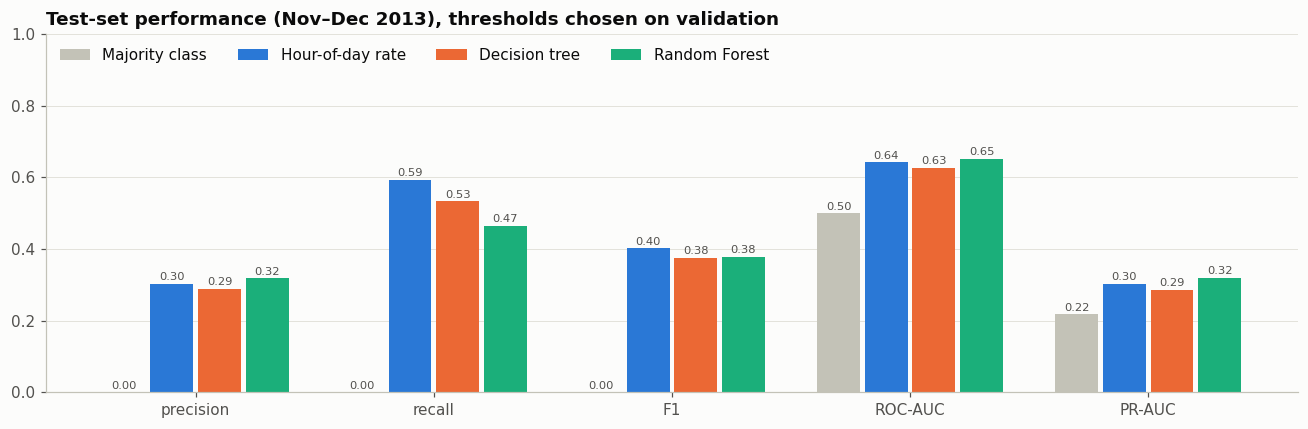

In [24]:
test_proba = {n: m.predict_proba(X_te)[:, 1] for n, m in models.items()}
test_results = pd.DataFrame([scores(n, y_te, p, thresholds[n]) for n, p in test_proba.items()]).set_index("model")
display(test_results)

MODEL_COL = {"Majority class": AXIS, "Hour-of-day rate": BLUE, "Decision tree": ORANGE, "Random Forest": AQUA}
metrics = ["precision", "recall", "F1", "ROC-AUC", "PR-AUC"]
fig, ax = plt.subplots(figsize=(12, 4))
w = 0.2
for k, name in enumerate(test_results.index):
    vals = test_results.loc[name, metrics].values.astype(float)
    xs = np.arange(len(metrics)) + (k - 1.5) * w
    ax.bar(xs, vals, width=w - 0.02, color=MODEL_COL[name], label=name)
    for x, v in zip(xs, vals):
        ax.text(x, v + 0.01, f"{v:.2f}", ha="center", fontsize=7.5, color=INK2)
ax.set_xticks(range(len(metrics)), metrics); ax.set_ylim(0, 1)
ax.set_title("Test-set performance (Nov–Dec 2013), thresholds chosen on validation")
ax.legend(ncol=4, loc="upper left"); no_grid(ax, "x")
plt.tight_layout(); plt.show()

**Interpretation.**

- **Ranking quality (threshold-free):** the **Random Forest is the best model** on the test set: **PR-AUC 0.320** vs. 0.303 for the hour baseline, 0.287 for the tree and 0.218 for random guessing. ROC-AUC is **0.652**. It carries over from validation to test, but the margin over the one-feature baseline is **small** (about +0.01 ROC-AUC, +0.02 PR-AUC).
- **Thresholded metrics:** at the thresholds chosen on validation, the **hour-of-day baseline has the best F1 on test (0.40 vs. 0.38 for RF)**. The reason is the **base-rate shift**: thresholds tuned on a calm autumn (14.9% delays) are too *conservative* for a December with 28.6% delays, so the RF flags too few flights in December (recall 0.47). The baseline's threshold happens to be less sensitive to this shift. F1 at a fixed threshold depends on both the model and the threshold, while PR-AUC and ROC-AUC measure the model alone.
- **The decision tree is the weakest learned model on test** (it beats only the majority class on PR-AUC). This fits the overfitting found in Section 6.3.
- **Overall:** the schedule features carry a **real but limited signal**, with ROC-AUC about 0.65–0.69. Most of the predictable structure is time of day, which a one-feature rule already captures. The ML models add a moderate gain on top of it.

### 7.1 Confusion matrices

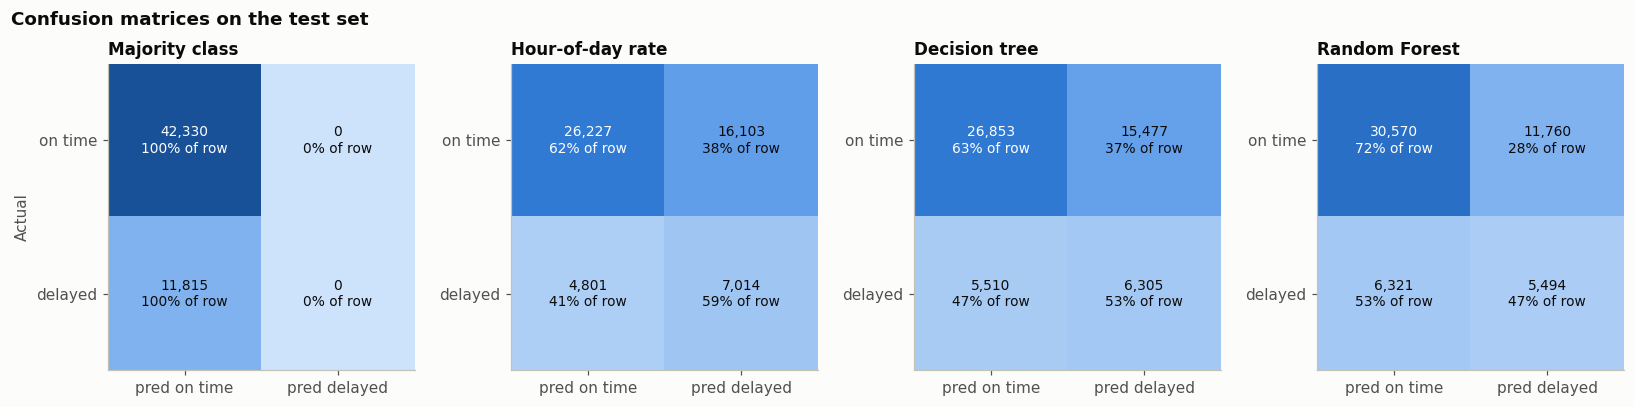

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, name in zip(axes, test_proba):
    cm = confusion_matrix(y_te, (test_proba[name] >= thresholds[name]).astype(int))
    ax.imshow(cm, cmap=SEQ, vmin=0, vmax=len(y_te))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n{cm[i, j]/cm[i].sum():.0%} of row", ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > len(y_te) * 0.45 else INK)
    ax.set_xticks([0, 1], ["pred on time", "pred delayed"]); ax.set_yticks([0, 1], ["on time", "delayed"])
    ax.set_title(name, fontsize=11); ax.grid(False)
axes[0].set_ylabel("Actual")
fig.suptitle("Confusion matrices on the test set", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretation.** The confusion matrices show the errors in absolute numbers. The majority baseline never predicts a delay. The **Random Forest is the most conservative learned model**: it raises fewer false alarms than the tree and the hour baseline (the "on time, predicted delayed" cell is smallest) but misses more delays. All models produce **many false positives**. With a precision of about 0.3, roughly 2 out of 3 "delay warnings" are false alarms. This is expected: schedule information can say that an evening EV flight from EWR is *risky*, but not whether *today* that risk will turn into an actual delay.

### 7.2 ROC and precision–recall curves

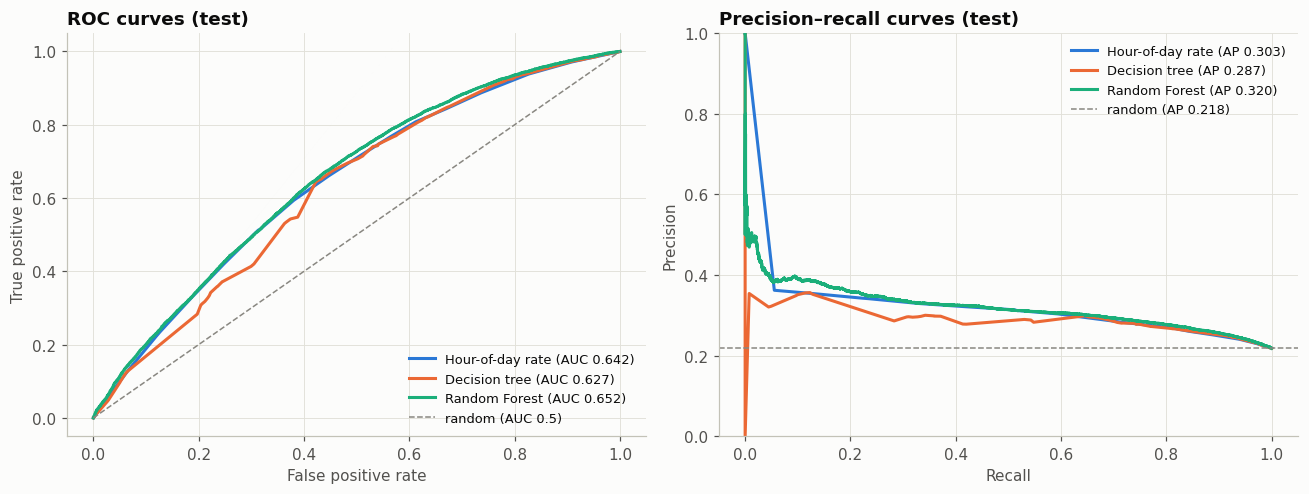

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
base = y_te.mean()
for name, p in test_proba.items():
    if name == "Majority class":
        continue
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[0].plot(fpr, tpr, color=MODEL_COL[name], label=f"{name} (AUC {roc_auc_score(y_te, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_te, p)
    axes[1].plot(rc, pr, color=MODEL_COL[name], label=f"{name} (AP {average_precision_score(y_te, p):.3f})")
axes[0].plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--", label="random (AUC 0.5)")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC curves (test)")
axes[1].axhline(base, color=MUTED, lw=1, ls="--", label=f"random (AP {base:.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision–recall curves (test)")
axes[1].set_ylim(0, 1)
for ax in axes: ax.legend(loc="upper right" if ax is axes[1] else "lower right", fontsize=8.5)
plt.tight_layout(); plt.show()

**Interpretation.** Both plots show the **whole range of thresholds**.

- **ROC:** the Random Forest and the hour-of-day baseline are **almost on top of each other** and clearly above the diagonal. The decision tree is slightly below both, with a "stepped" curve because it outputs only a limited number of distinct probabilities (one per leaf).
- **Precision–recall:** the RF's advantage is concentrated on the **left side of the curve, i.e. the most at-risk flights**. At low recall (the top ~10–15% of flagged delays) it keeps a **precision of about 0.38–0.40**, almost **twice the 22% base rate**, while the hour baseline drops quickly to about 0.36 (it can only tell hours apart, not flights within an hour). From about 30% recall onwards all models converge.
- The model is therefore most useful as a **ranking tool** ("which flights are most at risk?"), less so as a yes/no predictor.

### 7.3 Risk deciles and calibration

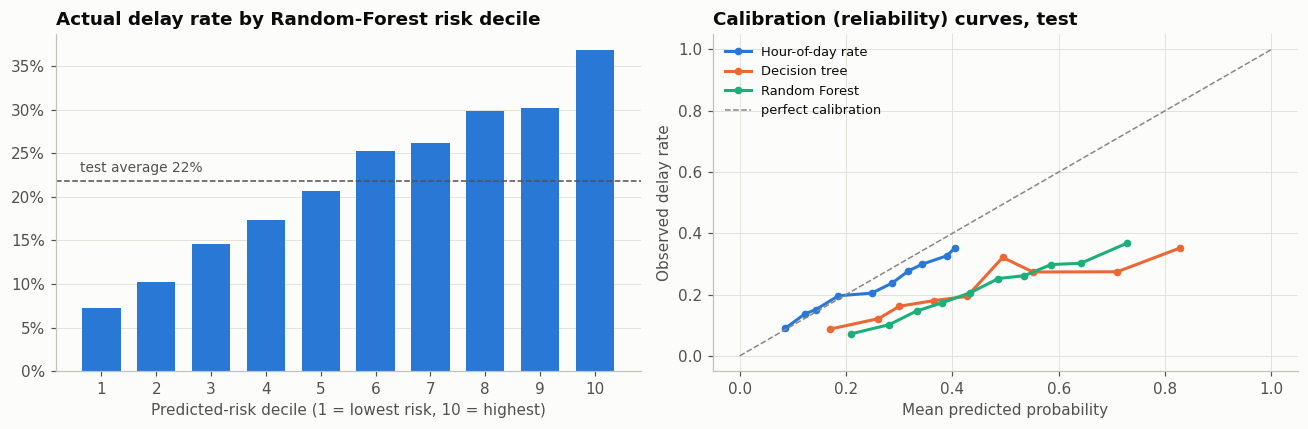

Top-decile delay rate: 36.8%  vs bottom decile: 7.2%  (lift ×1.69)


In [27]:
p_rf = test_proba["Random Forest"]
dec = pd.qcut(pd.Series(p_rf).rank(method="first"), 10, labels=range(1, 11))
lift = pd.DataFrame({"decile": dec.values, "y": y_te.values}).groupby("decile", observed=True).y.mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.bar(lift.index.astype(int), lift.values, color=BLUE, width=0.7)
ax.axhline(base, color=INK2, lw=1, ls="--"); ax.text(0.6, base + 0.01, f"test average {base:.0%}", fontsize=9, color=INK2)
pct(ax); no_grid(ax, "x"); ax.set_xticks(range(1, 11))
ax.set_xlabel("Predicted-risk decile (1 = lowest risk, 10 = highest)")
ax.set_title("Actual delay rate by Random-Forest risk decile")

ax = axes[1]
for name in ["Hour-of-day rate", "Decision tree", "Random Forest"]:
    frac_pos, mean_pred = calibration_curve(y_te, test_proba[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, color=MODEL_COL[name], marker="o", ms=4, label=name)
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--", label="perfect calibration")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed delay rate")
ax.set_title("Calibration (reliability) curves, test"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()
print(f"Top-decile delay rate: {lift.iloc[-1]:.1%}  vs bottom decile: {lift.iloc[0]:.1%}  (lift ×{lift.iloc[-1]/base:.2f})")

**Interpretation.**

- **Lift chart (left):** we sort the test flights by the Random Forest's predicted risk and split them into 10 equal groups. The actual delay rate increases **monotonically from 7.2% in the lowest-risk decile to 36.8% in the highest**, a **5× difference**. This is the clearest sign that the model has learned something useful. The top decile is delayed 1.7× more often than an average flight.
- **Calibration (right):** the **hour-of-day baseline is almost perfectly calibrated** (its predictions are training-set frequencies). The **tree and Random Forest systematically over-estimate the probability** (their curves lie below the diagonal), because `class_weight="balanced"` re-weights the training data to a 50/50 class ratio. This doesn't affect ranking (ROC/PR-AUC) and it's why their F1-optimal thresholds were around 0.5. If calibrated probabilities are needed (e.g. "this flight has a 35% chance of delay"), a post-hoc calibration step (Platt scaling or isotonic regression on the validation set) should be added, as the project plan promises a *probability* as output.

### 7.4 Which features does the Random Forest use?

We show two views. **Impurity importance** measures how much each feature reduces impurity inside the trees on the *training* data, with one-hot columns summed back to their original feature. **Permutation importance** measures how much test PR-AUC drops when the values of one feature are randomly shuffled, which shows what actually helps on *unseen* data.

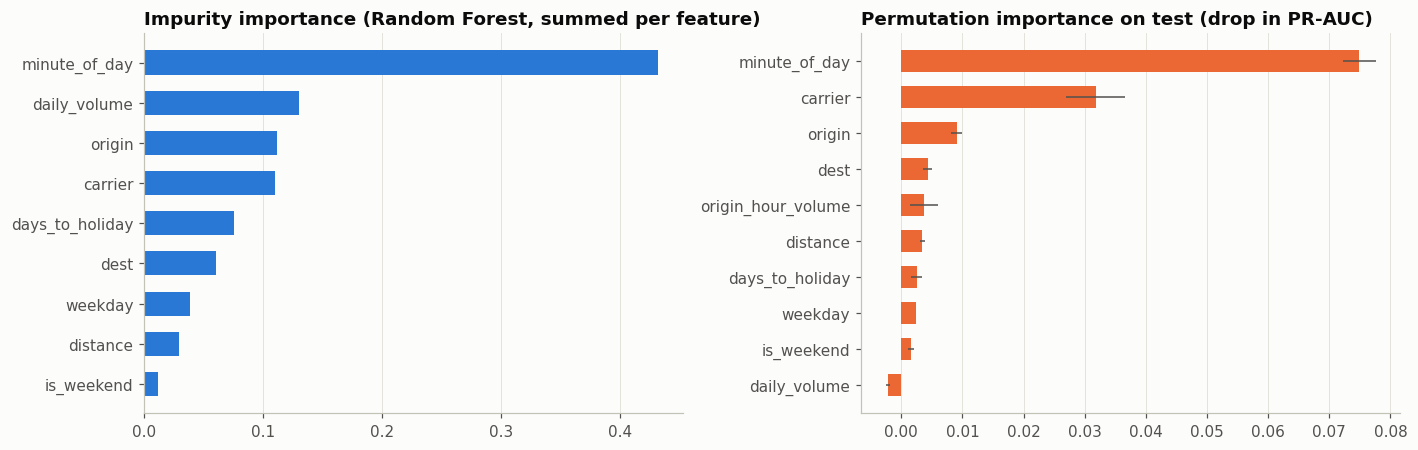

In [28]:
rf = models["Random Forest"]
names = rf.named_steps["pre"].get_feature_names_out()
def original(col):
    for c in CAT_FEATS:
        if col.startswith(c + "_"):
            return c
    return col
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=names).groupby(original).sum().sort_values()

sample = X_te.sample(20000, random_state=RANDOM_STATE)
perm = permutation_importance(rf, sample, y_te.loc[sample.index], scoring="average_precision",
                              n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=sample.columns).drop(EXTRA).sort_values()
perm_err = pd.Series(perm.importances_std, index=sample.columns).drop(EXTRA)[perm_s.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].barh(imp.index, imp.values, color=BLUE, height=0.6)
axes[0].set_title("Impurity importance (Random Forest, summed per feature)")
axes[1].barh(perm_s.index, perm_s.values, xerr=perm_err.values, color=ORANGE, height=0.6,
             error_kw={"ecolor": INK2, "elinewidth": 1})
axes[1].set_title("Permutation importance on test (drop in PR-AUC)")
for ax in axes: no_grid(ax, "y")
plt.tight_layout(); plt.show()

**Interpretation.**

- Both views agree that **`minute_of_day` is by far the most important feature**, followed by **`carrier`** and **`origin`**. This matches the EDA: time of day > airline > airport.
- **Disagreement on `daily_volume`:** it ranks **2nd by impurity** but **last, slightly *negative*, by permutation on test**. The forest uses it heavily during training, but it doesn't help, and even slightly hurts, on new data. Daily volume takes on few distinct values and almost **identifies individual dates**, so the trees use it to memorise *which days were bad* in the training period (e.g. storm days). This is a form of **overfitting through a proxy for the date**. Impurity importance is known to be biased toward features with many split points, which is why we also check permutation importance.
- `distance`, `weekday`, `is_weekend` and `days_to_holiday` contribute little once time of day and carrier are known.

The next cell tests the `daily_volume` hypothesis directly.

### 7.5 Ablation: removing `daily_volume`

ROC-AUC            PR-AUC           
split                       test validation   test validation
model                                                        
RF, all features           0.652      0.691  0.320      0.277
RF, without daily_volume   0.671      0.681  0.337      0.251

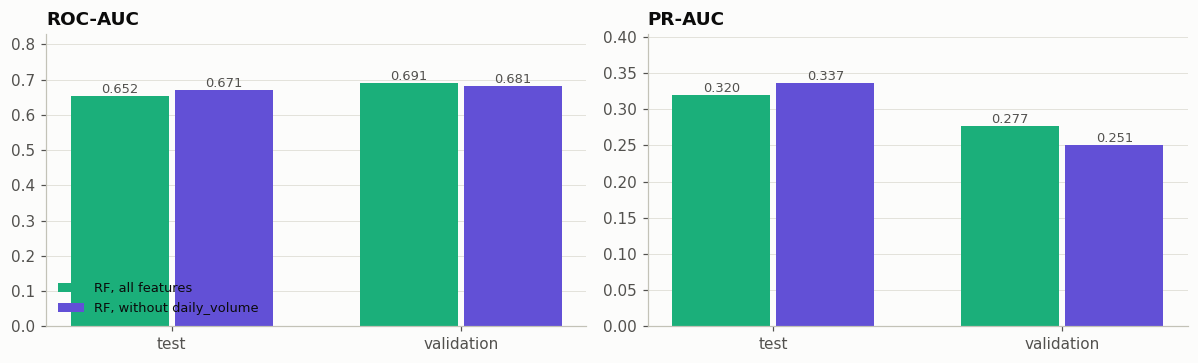

In [29]:
# Experiment: does the Random Forest generalise better WITHOUT daily_volume?
d, l = best_rf_key
NUM_NO_DV = [f for f in NUM_FEATS if f != "daily_volume"]
rf_no_dv = Pipeline([("pre", make_preprocessor(NUM_NO_DV)),
                     ("clf", RandomForestClassifier(n_estimators=150, max_depth=d, min_samples_leaf=l,
                                                    max_features="sqrt", class_weight="balanced_subsample",
                                                    n_jobs=-1, random_state=RANDOM_STATE))]).fit(X_tr, y_tr)
rows = []
for name, m in [("RF, all features", rf), ("RF, without daily_volume", rf_no_dv)]:
    for split, X_, y_ in [("validation", X_va, y_va), ("test", X_te, y_te)]:
        p = m.predict_proba(X_)[:, 1]
        rows.append({"model": name, "split": split, "ROC-AUC": roc_auc_score(y_, p), "PR-AUC": average_precision_score(y_, p)})
abl = pd.DataFrame(rows)
display(abl.pivot(index="model", columns="split", values=["ROC-AUC", "PR-AUC"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, metric in zip(axes, ["ROC-AUC", "PR-AUC"]):
    pv_ = abl.pivot(index="split", columns="model", values=metric)
    x = np.arange(len(pv_))
    for k, (col, c) in enumerate(zip(pv_.columns, [AQUA, VIOLET])):
        ax.bar(x + (k - 0.5) * 0.36, pv_[col], width=0.34, color=c, label=col)
        for xi, v in zip(x, pv_[col]):
            ax.text(xi + (k - 0.5) * 0.36, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8.5, color=INK2)
    ax.set_xticks(x, pv_.index); ax.set_title(metric); no_grid(ax, "x")
    ax.set_ylim(0, pv_.values.max() * 1.2)
axes[0].legend(loc="lower left", fontsize=8.5)
plt.tight_layout(); plt.show()

**Interpretation.** Removing `daily_volume` gives **mixed** results. The model gets **worse on validation** (PR-AUC 0.277 → 0.251) but **better on test** (PR-AUC 0.320 → 0.337; ROC-AUC 0.652 → 0.671). The relationship between daily volume and delays is therefore **not stable over time**: it held in Sep–Oct and broke in Nov–Dec, which have high volumes around Thanksgiving and Christmas but very different weather.

Following correct methodology, **we may not choose features based on the test set**, so the "official" model stays the one selected on validation. The experiment does tell us that a **single validation period is a fragile basis for model selection** with such strong seasonality. In the next stage we plan to use **rolling-origin (time-series) cross-validation** with several validation windows, and to replace `daily_volume` with a more robust traffic measure (e.g. the volume relative to the same weekday's average).

### 7.6 An interpretable decision tree

Random Forests are hard to read, so to *explain* the patterns we fit a separate, very shallow tree (depth 3). It is not used for prediction.

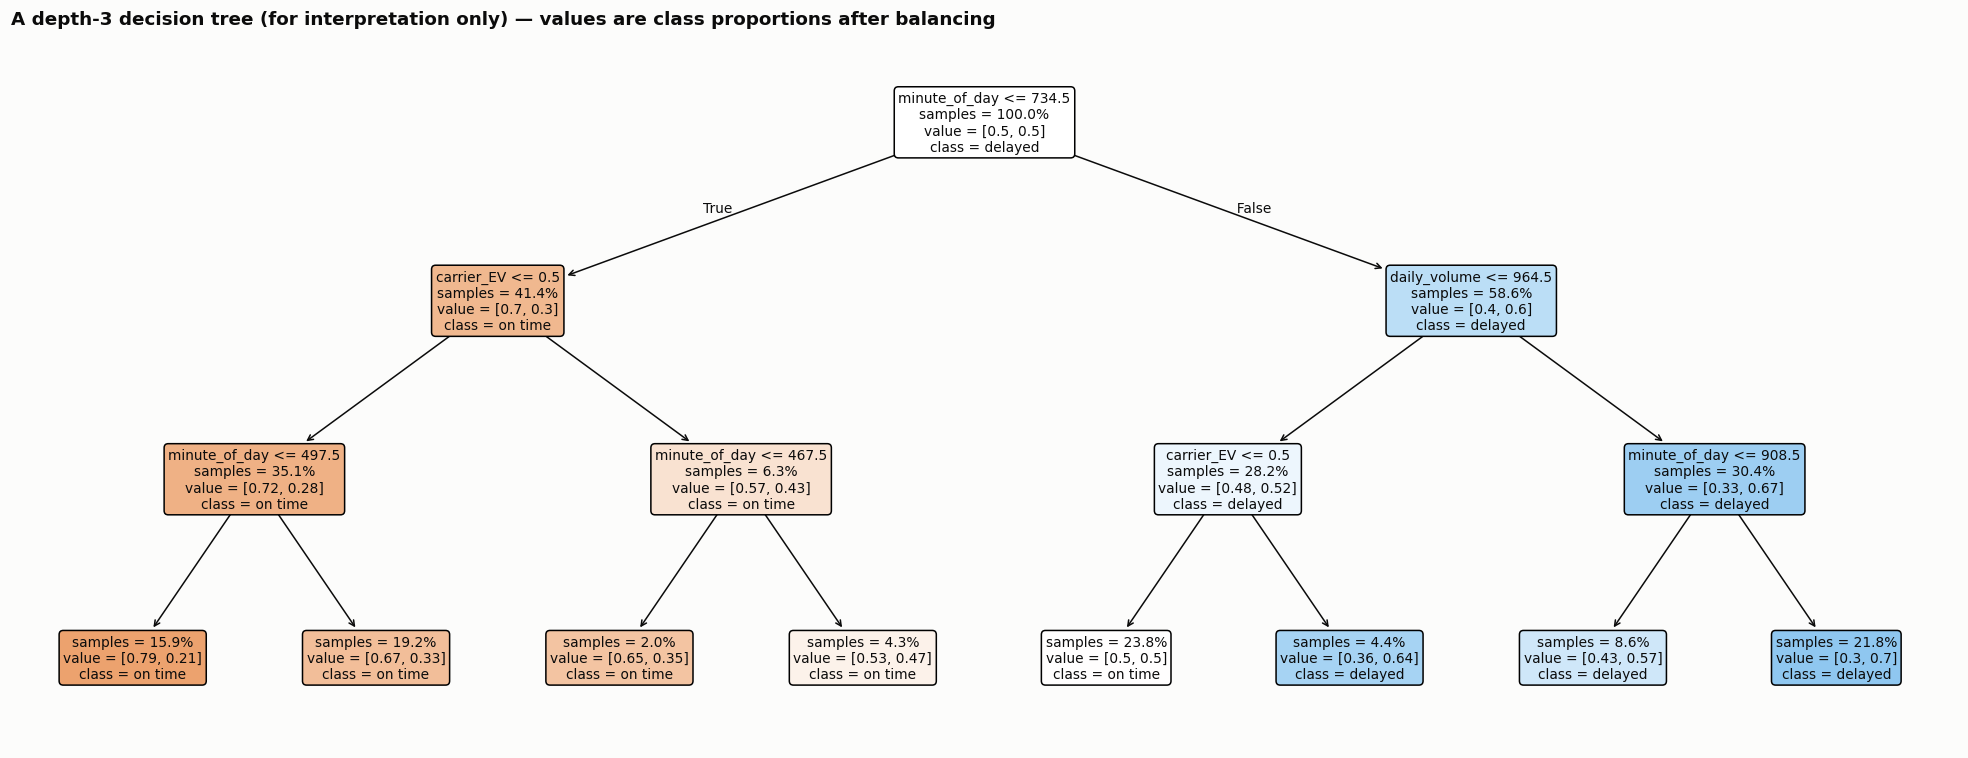

In [30]:
small_tree = Pipeline([("pre", make_preprocessor()),
                       ("clf", DecisionTreeClassifier(max_depth=3, min_samples_leaf=500, class_weight="balanced",
                                                      random_state=RANDOM_STATE))]).fit(X_tr, y_tr)
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(small_tree.named_steps["clf"], feature_names=small_tree.named_steps["pre"].get_feature_names_out(),
          class_names=["on time", "delayed"], filled=True, rounded=True, impurity=False, proportion=True,
          precision=2, fontsize=9, ax=ax)
ax.set_title("A depth-3 decision tree (for interpretation only) — values are class proportions after balancing")
plt.tight_layout(); plt.show()

**Interpretation.** The shallow tree gives a readable summary of the main rules:

1. **The first split is the scheduled time, around 12:15** (`minute_of_day ≤ 734.5`). Morning flights go left (mostly on time) and afternoon/evening flights go right (mostly delayed after class balancing).
2. **Mornings:** the next question is **"is it ExpressJet (EV)?"**. Non-EV flights before about 08:15 form the safest group in the whole tree.
3. **Afternoons:** the next split is **busy day vs. normal day** (`daily_volume`), followed again by time of day (after about 15:00) and EV. The riskiest leaf is **afternoon/evening flights after 15:00 on busy days**.

These rules match the exploratory analysis, which gives some confidence that the models learn real patterns rather than noise.

### 7.7 Error analysis: where does the model work best?

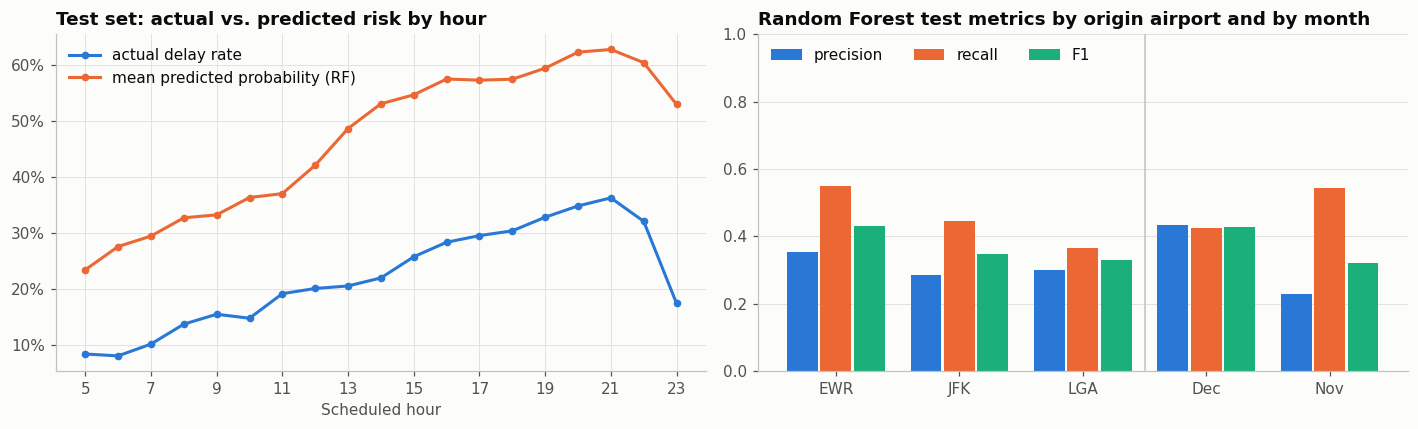

,flights,delay rate,precision,recall,F1
EWR,"19,071.000",0.253,0.353,0.551,0.430
JFK,"17,637.000",0.196,0.285,0.447,0.348
LGA,"17,437.000",0.203,0.300,0.366,0.330
Dec,"27,110.000",0.286,0.432,0.424,0.428
Nov,"27,035.000",0.150,0.229,0.543,0.322


In [31]:
res = test.assign(p=p_rf, pred=(p_rf >= thresholds["Random Forest"]).astype(int))
hourly = res[res.sched_hour.between(5, 23)].groupby("sched_hour").agg(actual=("delayed", "mean"), predicted=("p", "mean"))

def group_metrics(g):
    return pd.Series({"flights": len(g), "delay rate": g.delayed.mean(),
                      "precision": precision_score(g.delayed, g.pred, zero_division=0),
                      "recall": recall_score(g.delayed, g.pred), "F1": f1_score(g.delayed, g.pred)})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(hourly.index, hourly.actual, color=BLUE, marker="o", ms=4, label="actual delay rate")
ax.plot(hourly.index, hourly.predicted, color=ORANGE, marker="o", ms=4, label="mean predicted probability (RF)")
pct(ax); ax.set_xlabel("Scheduled hour"); ax.set_xticks(range(5, 24, 2)); ax.legend()
ax.set_title("Test set: actual vs. predicted risk by hour")

by_origin = res.groupby("origin").apply(group_metrics)
by_month = res.groupby(res.month.map({11: "Nov", 12: "Dec"})).apply(group_metrics)
seg = pd.concat([by_origin, by_month])
ax = axes[1]
x = np.arange(len(seg)); w = 0.27
for k, (mname, col) in enumerate(zip(["precision", "recall", "F1"], [BLUE, ORANGE, AQUA])):
    ax.bar(x + (k - 1) * w, seg[mname], width=w - 0.02, color=col, label=mname)
ax.set_xticks(x, seg.index); ax.set_ylim(0, 1); ax.legend(ncol=3); no_grid(ax, "x")
ax.axvline(2.5, color=AXIS, lw=1)
ax.set_title("Random Forest test metrics by origin airport and by month")
plt.tight_layout(); plt.show()
display(seg)

**Interpretation.**

- **By hour (left):** the RF **follows the shape of the real hourly pattern well**: predicted risk rises through the day and drops late at night, just like the actual rate. The whole curve is shifted upward because of the balanced class weights discussed in 7.3. The model has learned the correct *ranking* of hours.
- **By airport:** performance is best at **EWR (F1 0.43)**, the airport with the most delays and the strongest carrier effect (EV), and weakest at **LGA (F1 0.33)**.
- **By month:** this is the base-rate shift again. In **November** (15% delays) the model raises many false alarms (precision 0.23, recall 0.54). In **December** (29% delays) precision rises to 0.43 while recall falls. The same model with the same threshold behaves very differently in a calm month and a stormy month. This shows the model doesn't "know" about weather or day-level disruptions.

## 8. Conclusions and next steps

### Summary of initial results

| | Test ROC-AUC | Test PR-AUC | Test F1 |
|---|---|---|---|
| Majority class | 0.500 | 0.218 | 0.000 |
| Hour-of-day rate (baseline) | 0.642 | 0.303 | **0.402** |
| Decision tree (depth 8) | 0.627 | 0.287 | 0.375 |
| **Random Forest** | **0.652** | **0.320** | 0.378 |

### What we learned

1. **The data is clean and consistent.** We found no duplicates and no impossible times, and `dep_delay` matches the clock times exactly. The only real gaps are cancelled flights (2.45%, excluded) and four non-continental destinations without metadata (kept).
2. **Delays follow clear schedule patterns.** The strongest effect is **time of day** (6% at 05:00 → 38% at 21:00), followed by **airline** (EV 31% vs. US 13%), **origin airport** (EWR worst), **weekday** (Thu/Fri worst, Sat best) and a strong **seasonality** (June–July and December).
3. **A flight's schedule, airline and route *do* help predict delay risk, but only partly.** The best model (Random Forest) ranks flights clearly better than random. The riskiest 10% are delayed 5× more often than the safest 10%. Its overall discrimination is modest (ROC-AUC about 0.65–0.69) and only a little better than a simple rule based on departure hour.
4. **The main limitation is day-level disruption.** The daily delay rate varies from about 5% to 69% depending on weather and air-traffic conditions, which are not in our inputs. This explains most of the remaining error, as well as the gap between validation (calm autumn) and test (stormy December).

### Next steps

- **Add weather data.** `nycflights13` also contains an hourly `weather` table for the three airports (wind, visibility, precipitation, pressure). Weather *forecasts* are available before departure, so this is a legitimate and probably the most valuable addition.
- **More robust validation.** Use rolling-origin time-series cross-validation instead of a single validation window, and tune the decision threshold on data that covers several seasons.
- **Calibrate probabilities.** Apply isotonic or Platt calibration so that the model's output can be read as a real probability, as promised in the project plan.
- **Feature refinement.** Replace `daily_volume` with a de-seasonalised traffic measure, add carrier × origin interactions, and consider target encoding for destinations.
- **Additional models.** Try gradient boosting (e.g. `HistGradientBoostingClassifier`) and a logistic regression as an interpretable linear reference.
- **Cancellations.** Study whether treating cancellations as delays (or as a third class) changes the conclusions.